# 산업별 주가수익률의 금리민감도: 최종 실증분석

2016–2025년 일별 자료를 이용해 시장수익률을 통제한 산업별 금리민감도를 추정하고, 수익률곡선 요인·금리 방향·산업 재무특성으로 분석을 확장한다. 결과는 관측된 금리변화와 산업수익률의 조건부 관련성으로 해석하며 인과효과로 확대하지 않는다.

| 단계 | 질문 | 역할 |
|---|---|---|
| **Baseline** | 산업별 3년 금리베타가 서로 다른가? | 산업 간 차이 확인 |
| **H1** | 차이는 수익률곡선의 어느 요인에서 나타나는가? | 금리요인 분해 |
| **H2** | 금리 상승과 하락에 대한 반응은 다른가? | 방향 비대칭 검정 |
| **H3** | 산업 재무특성과 금리베타는 어떻게 정렬되는가? | 탐색적 해석 |

Baseline에서 산업 간 차이를 확인한 뒤 H1에서 만기와 수익률곡선 요인을 비교한다. H2는 상승·하락 계수의 동일성을 검정하고, H3는 산업 단위 순위관계를 탐색한다. 본문에 필요한 결과를 먼저 제시하고 세부 민감도와 기술적 진단은 Appendix에 둔다.


In [1]:
# 저장소 루트와 분석 환경 설정
import sys
from pathlib import Path

_anchors = []
if "__vsc_ipynb_file__" in globals():
    _anchors.append(Path(globals()["__vsc_ipynb_file__"]).resolve().parent)
if globals().get("_dh"):
    _anchors.append(Path(globals()["_dh"][0]).resolve())
_anchors.append(Path.cwd().resolve())

_root = next(
    (p for a in _anchors for p in [a, *a.parents]
     if (p / "config.py").is_file() and (p / "requirements.txt").is_file()),
    None,
)
if _root is None:
    raise FileNotFoundError("config.py와 requirements.txt가 있는 저장소 루트를 찾지 못했습니다.")
if str(_root) in sys.path:
    sys.path.remove(str(_root))
sys.path.insert(0, str(_root))

import config
from src import models

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from itertools import combinations, permutations
from scipy.optimize import minimize_scalar
from scipy.stats import spearmanr

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 120)
config.setup_korean_font(verbose=False)
plt.rcParams["axes.unicode_minus"] = False

NEG_COLOR, POS_COLOR, NS_COLOR = "#c0392b", "#1f6feb", "#9aa0a6"


def add_bh_correction(result, group_cols=("model",), p_col="p_value", alpha=0.05):
    """검정족(group_cols) 단위로 BH(FDR) 보정 p-value를 추가한다."""
    out = result.copy()
    group_cols = list(group_cols)
    out["p_value_bh"] = np.nan
    _by = group_cols[0] if len(group_cols) == 1 else group_cols
    for _, sub in out.groupby(_by):
        idx = sub.index
        out.loc[idx, "p_value_bh"] = multipletests(
            out.loc[idx, p_col].to_numpy(dtype=float), method="fdr_bh"
        )[1]
    out["significant_5pct_bh"] = out["p_value_bh"] < alpha
    return out


HAC_LAGS = config.HAC_MAXLAGS
print("분석 환경 준비 완료 · HAC lag =", HAC_LAGS, "· NS lambda =", config.NS_LAMBDA)


분석 환경 준비 완료 · HAC lag = 5 · NS lambda = 0.5


# 1. Baseline — 산업별 금리민감도 차이

## 연구질문과 검정

KOSPI 수익률을 통제한 뒤에도 산업별 3년 금리민감도가 서로 다른가?

$$
R_{i,t} = \alpha_i + \gamma_i R_{KOSPI,t} + \beta_{rate,i}\,\Delta y_{3,t} + \varepsilon_{i,t}
$$

$R_{i,t}$는 산업 $i$의 일별 수익률, $R_{KOSPI,t}$는 KOSPI 수익률, $\Delta y_{3,t}$는 국고채 3년물 금리의 일별 변화(%p)다. 산업별 계수는 HAC(Newey–West) 표준오차로 추정한다. 주 검정은 같은 날 산업들이 공유하는 충격을 고려한 날짜 클러스터 표준오차로 $H_0:\beta_1=\cdots=\beta_7$을 검정한다.


In [2]:
# 산업 · KOSPI · 금리 패널
panel = pd.read_csv(config.PROCESSED_DIR / "industry_rate_panel_daily.csv", encoding="utf-8-sig")
panel["date"] = pd.to_datetime(panel["date"])
industries = sorted(panel["industry"].unique())

print("표본 기간:", panel["date"].min().date(), "~", panel["date"].max().date())
print("산업 수:", len(industries), "|", industries)

# 산업별 개별 회귀(HAC) + 7개 산업에 대한 BH(FDR) 보정
beta_table = models.industry_rate_betas(panel)
baseline_table = (
    beta_table[["industry", "beta_rate", "p_value_bh"]]
    .rename(columns={"industry": "산업", "beta_rate": "3년 금리베타", "p_value_bh": "BH p-value"})
)
baseline_table["방향"] = np.where(
    beta_table["p_value_bh"] >= 0.05, "비유의",
    np.where(beta_table["beta_rate"] > 0, "유의한 +", "유의한 -"),
)
baseline_table.round(5)

표본 기간: 2016-01-04 ~ 2025-12-30
산업 수: 7 | ['건설업', '금융업', '운수장비', '의약품', '전기전자', '철강금속', '화학']


,산업,3년 금리베타,BH p-value,방향
0,건설업,0.00320,0.71155,비유의
1,금융업,0.01123,0.00822,유의한 +
2,운수장비,0.01723,0.00822,유의한 +
3,의약품,-0.02707,0.00384,유의한 -
4,전기전자,0.00159,0.71155,비유의
5,철강금속,0.01884,0.02862,유의한 +
6,화학,0.00256,0.71155,비유의


## 산업별 계수

- **의약품은 유의한 음(-)의 금리베타를 보였다.**
- 금융업·운수장비·철강금속은 유의한 양(+)의 금리베타를 보였다.
- 건설업·전기전자·화학은 BH 보정 후 유의수준에 도달하지 않았다.

아래 그림은 산업별 점추정과 95% 신뢰구간을 비교한다. 색은 BH 보정 후 방향과 유의성을 나타낸다.


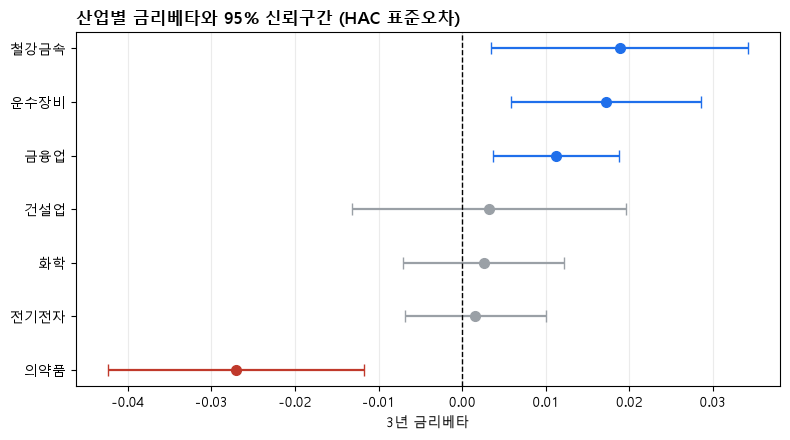

In [3]:
# 산업별 금리베타 계수 플롯 (95% 신뢰구간, BH 유의성 기준 색상)
beta_plot = beta_table.assign(color=[
    (NEG_COLOR if b < 0 else POS_COLOR) if p < 0.05 else NS_COLOR
    for b, p in zip(beta_table["beta_rate"], beta_table["p_value_bh"])
]).sort_values("beta_rate")

fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(beta_plot))
for yi, row in zip(y, beta_plot.itertuples()):
    lower, upper = row.beta_rate - row.ci_lower, row.ci_upper - row.beta_rate
    ax.errorbar(row.beta_rate, yi, xerr=[[lower], [upper]], fmt="o", markersize=7,
                capsize=4, elinewidth=1.6, ecolor=row.color, color=row.color)
ax.axvline(0, linestyle="--", linewidth=1, color="black")
ax.set_yticks(y)
ax.set_yticklabels(beta_plot["industry"])
ax.set_xlabel("3년 금리베타")
ax.set_title("산업별 금리베타와 95% 신뢰구간 (HAC 표준오차)", loc="left", fontweight="bold")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

의약품은 음(-) 방향에 위치한 반면 금융업·운수장비·철강금속은 양(+) 방향에 위치한다. 이 그림은 계수의 방향과 불확실성을 보여주지만 산업 간 차이의 유의성은 다음 공동검정으로 판단한다.


In [4]:
# 산업 간 금리베타 동일성 공동검정 (H0: 7개 산업의 금리베타가 모두 같다)
# 날짜 클러스터 표준오차 — 같은 날 여러 산업이 함께 받는 충격(횡단면 잔차 상관)을 보정한다.
joint_test = models.cross_industry_Ftest(
    panel.rename(columns={"industry_return": "ret", "kospi_return": "mkt", "d_y3": "dY"})
    [["industry", "ret", "mkt", "dY", "date"]]
)
print(f"공동검정(날짜 클러스터 SE): F = {float(joint_test.fvalue):.3f}, p = {float(joint_test.pvalue):.5f}")

공동검정(날짜 클러스터 SE): F = 4.189, p = 0.00034


## 결과와 해석 범위

**산업별 금리베타의 동일성은 기각되었다**(날짜 클러스터 F=4.189, p=0.00034). 시장수익률을 통제한 뒤에도 산업별 3년 금리민감도에는 통계적으로 유의한 차이가 있다.

양(+)의 계수를 금리상승의 인과효과로 읽지는 않는다. 관측된 금리변화에는 경기·물가 정보가 함께 포함될 수 있다. 정상국(2003)의 산업별 지수 사용, Sweeney & Warga(1986)의 시장·금리 2요인 모형, Bernanke & Kuttner(2005)의 시장요인 통제 논리는 이 모형의 설계 근거다.

Baseline은 산업 간 차이를 확인한다. 다음 H1에서는 이 차이가 단일 3년물에 한정되는지, 수익률곡선의 어느 요인에서 나타나는지 살펴본다.


# 2. H1 — 만기와 수익률곡선 요인

## 3년·10년·장단기차 연결

Baseline의 3년물 결과에서 바로 수익률곡선 요인으로 넘어가기 전에 3년물, 10년물, 장단기차(10Y−3Y)의 산업별 HAC 회귀를 비교한다. 이 비교는 단일 만기에서 곡선의 수준·기울기·곡률로 확장하는 연결 단계다.


In [5]:
# 기존 만기별 HAC 회귀 결과를 불러와 연결표를 구성한다.
maturity_results = pd.read_csv(config.H1_TABDIR / "maturity_beta_comparison.csv")
maturity_order = ["3Y", "10Y", "Term_Spread"]
maturity_role = {
    "3Y": "Baseline",
    "10Y": "장기금리 비교",
    "Term_Spread": "기울기 대리",
}

bridge_rows = []
for model_name in maturity_order:
    sub = maturity_results[maturity_results["model"] == model_name]
    pharma = sub.loc[sub["industry"] == "의약품"].iloc[0]
    bridge_rows.append({
        "금리 변수": model_name,
        "개별 p<0.05 산업 수": int((sub["p_value"] < 0.05).sum()),
        "의약품 계수": pharma["coefficient"],
        "의약품 p-value": pharma["p_value"],
        "역할": maturity_role[model_name],
    })
maturity_bridge = pd.DataFrame(bridge_rows)
maturity_bridge.round(4)


,금리 변수,개별 p<0.05 산업 수,의약품 계수,의약품 p-value,역할
0,3Y,4,-0.0271,0.0005,Baseline
1,10Y,2,-0.0160,0.0697,장기금리 비교
2,Term_Spread,0,0.0296,0.0913,기울기 대리


3년물에서는 네 산업의 개별 계수가 5% 수준에 도달하지만 10년물에서는 패턴이 약해지고, 장단기차에서는 개별 유의 산업이 확인되지 않는다. 이 표는 산업별 개별 HAC 회귀의 비교이며, 산업 간 동일성에 대한 주 검정은 Baseline의 날짜 클러스터 공동검정이다.

만기별 결과만으로 곡선 움직임의 성격을 분리하기는 어렵다. 이에 국고채 1·3·5·10년을 Nelson–Siegel Level·Slope·Curvature로 분해한다.


## Nelson–Siegel 요인분해

H1의 질문은 개별 요인계수가 0인지보다 **같은 요인의 계수가 산업마다 같은지**이다. 감쇠계수는 요인 분리를 기준으로 $\lambda=0.5$를 사용하고, 곡선 재구성 오차가 가장 작은 $\lambda=0.8041$을 민감도 비교값으로 둔다.

$$
R_{i,t} = \alpha_i + \gamma_i R_{KOSPI,t} + \beta_{L,i}\Delta Level_t + \beta_{S,i}\Delta Slope_t + \beta_{C,i}\Delta Curvature_t + \varepsilon_{i,t}
$$


In [6]:
# 확장 산업 패널(NS 요인·신용스프레드 포함)
extended_panel = pd.read_csv(config.EXTENDED_PANEL_PATH, encoding="utf-8-sig")
extended_panel["date"] = pd.to_datetime(extended_panel["date"], errors="coerce")
print("확장 패널:", extended_panel.shape, "| NS lambda =", config.NS_LAMBDA)


def run_yield_curve_factor_model(data, hac_lags=HAC_LAGS, x_cols=None, factor_labels=None):
    """산업별 다요인 동시모형(HAC)."""
    if x_cols is None:
        x_cols = ["kospi_return", "d_ns_level", "d_ns_slope", "d_ns_curvature"]
    if factor_labels is None:
        factor_labels = {"d_ns_level": "Level", "d_ns_slope": "Slope", "d_ns_curvature": "Curvature"}

    rows = []
    for industry, group in data.groupby("industry"):
        reg_data = group[["industry_return"] + x_cols].dropna()
        X = sm.add_constant(reg_data[x_cols], has_constant="add")
        model = sm.OLS(reg_data["industry_return"], X).fit(
            cov_type="HAC", cov_kwds={"maxlags": hac_lags}
        )
        for variable, factor in factor_labels.items():
            rows.append({
                "industry": industry,
                "factor": factor,
                "coefficient": model.params[variable],
                "std_error_hac": model.bse[variable],
                "t_value": model.tvalues[variable],
                "p_value": model.pvalues[variable],
            })
    return pd.DataFrame(rows)


yield_curve_factor_betas = run_yield_curve_factor_model(extended_panel)
(
    yield_curve_factor_betas[yield_curve_factor_betas["factor"] == "Curvature"]
    .rename(columns={"industry": "산업", "coefficient": "Curvature 계수", "p_value": "p-value"})
    [["산업", "Curvature 계수", "p-value"]]
    .round(6)
)


확장 패널: (17164, 32) | NS lambda = 0.5


,산업,Curvature 계수,p-value
2,건설업,-0.002338,0.444568
5,금융업,0.002413,0.078067
8,운수장비,0.006207,0.007206
11,의약품,-0.008599,0.002363
14,전기전자,0.001441,0.362277
17,철강금속,0.004148,0.149483
20,화학,-0.000080,0.962436


Curvature 계수는 의약품에서 −0.00860, 운수장비에서 +0.00621로 나타났다. 두 산업은 같은 곡률 변화에 반대 방향의 조건부 반응을 보였다.


In [7]:
def run_industry_difference_test(data, test_vars, model_name,
                                  ret_col="industry_return", mkt_col="kospi_return",
                                  industry_col="industry", date_col="date"):
    """H0: 모든 산업의 계수가 같다(요인별 F검정). 날짜 클러스터 표준오차."""
    test_vars = list(test_vars)
    d = data.dropna(subset=[ret_col, mkt_col, industry_col, date_col] + test_vars).copy()
    date_codes = pd.factorize(d[date_col])[0]

    dummies = pd.get_dummies(d[industry_col], prefix="ind", dtype=float)
    blocks = [dummies, dummies.mul(d[mkt_col].values, axis=0).add_prefix("mkt_")]
    for v in test_vars:
        blocks.append(dummies.mul(d[v].values, axis=0).add_prefix(f"{v}__"))
    X = pd.concat(blocks, axis=1)
    names = list(X.columns)

    model = sm.OLS(d[ret_col].values, X.values).fit(cov_type="cluster", cov_kwds={"groups": date_codes})

    rows = []
    for v in test_vars:
        idx = [i for i, c in enumerate(names) if c.startswith(f"{v}__")]
        R = np.zeros((len(idx) - 1, len(names)))
        for r, j in enumerate(idx[1:]):
            R[r, idx[0]] = 1.0
            R[r, j] = -1.0
        t = model.f_test(R)
        rows.append({"model": model_name, "variable": v, "f_stat": float(t.fvalue), "p_value": float(t.pvalue)})
    return pd.DataFrame(rows)


industry_difference_test = pd.concat([
    run_industry_difference_test(extended_panel, ["d_ns_level", "d_ns_slope", "d_ns_curvature"], "B_ThreeFactor"),
    run_industry_difference_test(extended_panel, ["d_ns_level", "d_ns_slope", "d_ns_curvature", "d_credit_spread"], "C_FourFactor"),
], ignore_index=True)

FACTOR_NAME = {"d_ns_level": "Level", "d_ns_slope": "Slope", "d_ns_curvature": "Curvature", "d_credit_spread": "CreditSpread"}
industry_difference_test.insert(2, "factor", industry_difference_test["variable"].map(FACTOR_NAME))
industry_difference_test = add_bh_correction(industry_difference_test, group_cols=("model",))

# 본문 표: Level·Slope·Curvature는 3요인 모형, Credit Spread는 4요인 모형 기준
h1_headline = pd.concat([
    industry_difference_test[(industry_difference_test["model"] == "B_ThreeFactor")],
    industry_difference_test[(industry_difference_test["model"] == "C_FourFactor") & (industry_difference_test["factor"] == "CreditSpread")],
])[["factor", "f_stat", "p_value_bh"]].rename(columns={"factor": "요인", "f_stat": "산업 간 F", "p_value_bh": "BH p-value"})
h1_headline.round(4)

,요인,산업 간 F,BH p-value
0,Level,1.4724,0.2755
1,Slope,1.2363,0.2843
2,Curvature,3.5800,0.0047
6,CreditSpread,1.0833,0.3699


## 산업 간 동일성 검정

| 요인 | 판단 |
|---|---|
| Level (F=1.472, BH p=0.2755) | 산업 간 차이 확인 안 됨 |
| Slope (F=1.236, BH p=0.2843) | 산업 간 차이 확인 안 됨 |
| **Curvature (F=3.580, BH p=0.0047)** | **$\lambda=0.5$에서 산업 간 차이 관찰** |
| Credit Spread (F=1.083, BH p=0.3699) | 산업 간 차이 확인 안 됨 |

아래 그림은 네 요인의 산업 간 동일성 검정 BH p-value를 같은 축에서 비교한다.


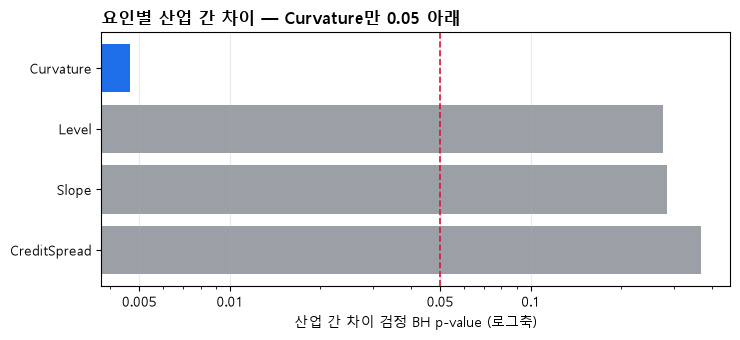

In [8]:
# 요인별 산업 간 차이 검정 p-value 비교 (로그축, 붉은 점선 = 0.05)
plot_h1 = h1_headline.sort_values("BH p-value", ascending=False)
colors = [POS_COLOR if p < 0.05 else NS_COLOR for p in plot_h1["BH p-value"]]

fig, ax = plt.subplots(figsize=(7.5, 3.5))
y = np.arange(len(plot_h1))
ax.barh(y, plot_h1["BH p-value"], color=colors)
ax.axvline(0.05, linestyle="--", linewidth=1.2, color="crimson")
ax.set_xscale("log")
ax.set_xticks([0.005, 0.01, 0.05, 0.1])
ax.set_xticklabels(["0.005", "0.01", "0.05", "0.1"])
ax.set_yticks(y)
ax.set_yticklabels(plot_h1["요인"])
ax.set_xlabel("산업 간 차이 검정 BH p-value (로그축)")
ax.set_title("요인별 산업 간 차이 — Curvature만 0.05 아래", loc="left", fontweight="bold")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

Curvature만 5% 기준 아래에 있다. Level·Slope·Credit Spread의 비유의 결과는 모든 금리요인에서 산업 차이가 나타나는 것은 아님을 보여준다.


In [9]:
# 국고채 1·3·5·10년 '변화분'의 주성분분석 — 수익률곡선이 실질적으로 몇 차원인지 확인
YIELD_CHANGE_COLS = ["d_y1", "d_y3_new", "d_y5", "d_y10_new"]
yield_changes = (
    extended_panel[["date"] + YIELD_CHANGE_COLS]
    .drop_duplicates(subset="date").dropna().sort_values("date")
)
Z = yield_changes[YIELD_CHANGE_COLS].to_numpy(dtype=float)
Z_centered = Z - Z.mean(axis=0)
eigenvalues, _ = np.linalg.eigh(np.cov(Z_centered, rowvar=False))
eigenvalues = eigenvalues[::-1]
explained = eigenvalues / eigenvalues.sum()

print(f"PC1 설명비중: {explained[0]*100:.2f}%   PC1+PC2: {explained[:2].sum()*100:.2f}%")

PC1 설명비중: 92.09%   PC1+PC2: 96.88%


## 해석의 범위

PC1은 금리곡선 변화의 92.09%를 설명한다. 표본기간의 국고채 금리는 대부분 함께 움직였으므로 Level·Slope·Curvature를 완전히 독립적인 충격으로 해석하기 어렵다.

**대체 $\lambda=0.8041$에서는 Curvature의 산업 간 차이가 5% 수준에서 유지되지 않았다**(BH p=0.0998). 따라서 Curvature 결과는 $\lambda=0.5$ 설정에서 관찰된 조건부 결과다. 곡률이 산업 차이의 확정적 원인이라고 보지 않는다.

직교화와 FWL 검증은 공유변동과 계수 구조를 확인하는 기술적 진단이다. Curvature와 Credit Spread가 일부 변동을 공유한다는 사실만으로 어느 변수에 경제적 효과가 귀속되는지는 식별되지 않는다. 세부 민감도는 Appendix B에 제시한다.

H1은 산업 차이가 곡률에서 관찰될 수 있음을 보이지만 설정 의존성도 함께 드러낸다. H2는 요인 분해와 별개로 금리 상승과 하락의 반응이 같은지 직접 검정한다.


# 3. H2 — 금리 상승·하락 비대칭

## 연구질문과 검정

금리 상승과 하락에 대한 산업별 반응은 서로 다른가?

$$
R_{i,t} = \alpha_i + \gamma_i R_{KOSPI,t} + \beta_{up,i}\Delta y_{3,t}^{up} + \beta_{down,i}\Delta y_{3,t}^{down} + \varepsilon_{i,t}
$$

$\Delta y_{3,t}^{up}=\max(\Delta y_{3,t},0)$, $\Delta y_{3,t}^{down}=\min(\Delta y_{3,t},0)$이다. H2의 질문은 두 계수가 각각 0인지가 아니라 서로 같은지이다. 따라서 $H_0:\beta_{up}=\beta_{down}$을 Wald 검정하고 산업별 p-value에 BH 보정을 적용한다.


In [10]:
# 상승분·하락분 변수 생성 (3년물·Curvature)
extended_panel["d_y3_up"] = extended_panel["d_y3"].clip(lower=0)
extended_panel["d_y3_down"] = extended_panel["d_y3"].clip(upper=0)
extended_panel["d_curv_up"] = extended_panel["d_ns_curvature"].clip(lower=0)
extended_panel["d_curv_down"] = extended_panel["d_ns_curvature"].clip(upper=0)

n_up = int((extended_panel.drop_duplicates("date")["d_y3"] > 0).sum())
n_down = int((extended_panel.drop_duplicates("date")["d_y3"] < 0).sum())
n_zero = int((extended_panel.drop_duplicates("date")["d_y3"] == 0).sum())
print(f"표본 구성: 상승 {n_up}일 · 하락 {n_down}일 · 무변화 {n_zero}일")


def fit_asymmetric(data, up, down, hac_lags=HAC_LAGS):
    use_cols = ["industry_return", "kospi_return", up, down]
    sample = data[use_cols].replace([np.inf, -np.inf], np.nan).dropna()
    X = sm.add_constant(sample[["kospi_return", up, down]], has_constant="add")
    return sm.OLS(sample["industry_return"], X).fit(cov_type="HAC", cov_kwds={"maxlags": hac_lags})


rows_wald = []
for ind in industries:
    g = extended_panel[extended_panel["industry"] == ind]
    m = fit_asymmetric(g, "d_y3_up", "d_y3_down")
    w = m.f_test("d_y3_up = d_y3_down")
    rows_wald.append({
        "industry": ind, "beta_up": m.params["d_y3_up"], "beta_down": m.params["d_y3_down"],
        "f_stat": float(w.fvalue), "p_value": float(w.pvalue),
    })
asymmetry_wald_tests = pd.DataFrame(rows_wald)
asymmetry_wald_tests["p_value_bh"] = multipletests(asymmetry_wald_tests["p_value"], method="fdr_bh")[1]
asymmetry_wald_tests.round(5)

표본 구성: 상승 1203일 · 하락 1197일 · 무변화 51일


,industry,beta_up,beta_down,f_stat,p_value,p_value_bh
0,건설업,-0.02161,0.03103,10.41780,0.00126,0.00885
1,금융업,0.00566,0.01748,1.11376,0.29137,0.42965
2,운수장비,0.01745,0.01699,0.00102,0.97451,0.97451
3,의약품,-0.01716,-0.03818,1.11250,0.29164,0.42965
4,전기전자,0.00784,-0.00542,1.65486,0.19842,0.42965
5,철강금속,0.02813,0.00841,1.04444,0.30689,0.42965
6,화학,0.00094,0.00437,0.07558,0.78341,0.91398


아래 그림은 각 산업의 상승·하락 계수를 연결해 두 계수의 간격과 부호를 보여준다. 별표는 Wald 검정의 BH p-value가 0.05 미만인 경우다.


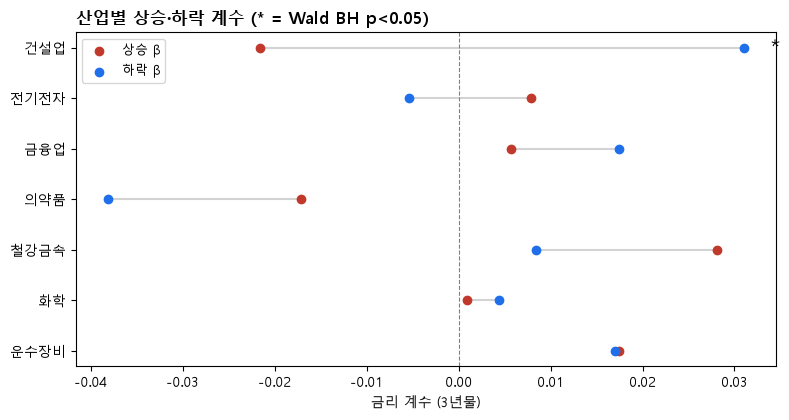

In [11]:
# 산업별 상승·하락 계수 비교 (별표 = Wald BH p<0.05)
plot_w = asymmetry_wald_tests.sort_values("f_stat")
fig, ax = plt.subplots(figsize=(8, 4.3))
y = np.arange(len(plot_w))
ax.scatter(plot_w["beta_up"], y, color=NEG_COLOR, label="상승 β", zorder=3)
ax.scatter(plot_w["beta_down"], y, color=POS_COLOR, label="하락 β", zorder=3)
for yi, (_, row) in zip(y, plot_w.iterrows()):
    ax.plot([row["beta_up"], row["beta_down"]], [yi, yi], color="lightgray", zorder=1)
    if row["p_value_bh"] < 0.05:
        ax.text(max(row["beta_up"], row["beta_down"]) + 0.003, yi, "*", fontsize=14, va="center", color="black")
ax.axvline(0, color="gray", lw=0.8, ls="--")
ax.set_yticks(y)
ax.set_yticklabels(plot_w["industry"])
ax.set_xlabel("금리 계수 (3년물)")
ax.set_title("산업별 상승·하락 계수 (* = Wald BH p<0.05)", loc="left", fontweight="bold")
ax.legend(loc="best", frameon=True, fontsize=9)
fig.tight_layout()
plt.show()

## 핵심 결과

**건설업에서만 BH 보정 후 상승·하락 계수의 차이가 확인되었다**: $\beta_{up}=-0.0216$, $\beta_{down}=+0.0310$, Wald F=10.4178, BH p=0.0089. 나머지 여섯 산업에서는 비대칭이 확인되지 않았다.


In [12]:
# 대칭모형과의 비교 — 건설업 대칭 β는 방향 분리 전에는 유의하지 않았다
sym_rows = []
for ind in industries:
    g = extended_panel[extended_panel["industry"] == ind][["industry_return", "kospi_return", "d_y3"]].dropna()
    X = sm.add_constant(g[["kospi_return", "d_y3"]], has_constant="add")
    m = sm.OLS(g["industry_return"], X).fit(cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS})
    sym_rows.append({"industry": ind, "beta_symmetric": m.params["d_y3"], "p_symmetric": m.pvalues["d_y3"]})
symmetric_betas = pd.DataFrame(sym_rows)

con_sym = symmetric_betas[symmetric_betas["industry"] == "건설업"].iloc[0]
con_wald = asymmetry_wald_tests[asymmetry_wald_tests["industry"] == "건설업"].iloc[0]
print(f"건설업 대칭모형: beta={con_sym['beta_symmetric']:+.4f}, p={con_sym['p_symmetric']:.4f}")
print(f"건설업 방향분리: up={con_wald['beta_up']:+.4f}, down={con_wald['beta_down']:+.4f}, "
      f"Wald F={con_wald['f_stat']:.4f}, BH p={con_wald['p_value_bh']:.4f}")

건설업 대칭모형: beta=+0.0032, p=0.7008
건설업 방향분리: up=-0.0216, down=+0.0310, Wald F=10.4178, BH p=0.0089


대칭모형의 건설업 계수는 +0.0032(p=0.7008)로 유의하지 않았다. 방향을 분리하면 상승·하락 계수가 반대 부호로 나타난다. 하락분은 0 이하이므로 $\beta_{down}>0$인 항도 수익률에는 음(-)의 기여를 한다. 이 패턴은 평균계수에서 상쇄되던 방향별 반응이 분리모형에서 드러난 경우다.


In [13]:
def joint_symmetry_test(data, up, down, date_col="date"):
    """H0: 모든 산업 i에 대해 beta_up_i = beta_down_i (7개 제약). 날짜 클러스터 SE."""
    d = data.dropna(subset=["industry", "industry_return", "kospi_return", date_col, up, down]).copy()
    date_codes = pd.factorize(d[date_col])[0]
    dummies = pd.get_dummies(d["industry"], prefix="ind", dtype=float)
    X = pd.concat([
        dummies,
        dummies.mul(d["kospi_return"].values, axis=0).add_prefix("mkt_"),
        dummies.mul(d[up].values, axis=0).add_prefix(f"{up}__"),
        dummies.mul(d[down].values, axis=0).add_prefix(f"{down}__"),
    ], axis=1)
    res = sm.OLS(d["industry_return"].values, X.values).fit(cov_type="cluster", cov_kwds={"groups": date_codes})
    names = list(X.columns)
    iu = [i for i, c in enumerate(names) if c.startswith(f"{up}__")]
    idn = [i for i, c in enumerate(names) if c.startswith(f"{down}__")]
    R = np.zeros((len(iu), len(names)))
    for k, (a, b) in enumerate(zip(iu, idn)):
        R[k, a], R[k, b] = 1.0, -1.0
    return res.f_test(R)


joint_y3 = joint_symmetry_test(extended_panel, "d_y3_up", "d_y3_down")
joint_curv = joint_symmetry_test(extended_panel, "d_curv_up", "d_curv_down")
print(f"전 산업 동시검정 — 3년물:   F(7)={float(joint_y3.fvalue):.4f}, p={float(joint_y3.pvalue):.4f}")
print(f"전 산업 동시검정 — Curvature: F(7)={float(joint_curv.fvalue):.4f}, p={float(joint_curv.pvalue):.4f}")

# Curvature 방향분해 — 산업별 Wald
curv_wald_rows = []
for ind in industries:
    g = extended_panel[extended_panel["industry"] == ind]
    m = fit_asymmetric(g, "d_curv_up", "d_curv_down")
    w = m.f_test("d_curv_up = d_curv_down")
    curv_wald_rows.append({"industry": ind, "f_stat": float(w.fvalue), "p_value": float(w.pvalue)})
curvature_wald_tests = pd.DataFrame(curv_wald_rows)
curvature_wald_tests["p_value_bh"] = multipletests(curvature_wald_tests["p_value"], method="fdr_bh")[1]
curvature_wald_tests.round(5)

전 산업 동시검정 — 3년물:   F(7)=2.1039, p=0.0401
전 산업 동시검정 — Curvature: F(7)=0.7644, p=0.6173


,industry,f_stat,p_value,p_value_bh
0,건설업,0.52478,0.46888,0.78409
1,금융업,0.01180,0.91351,0.91351
2,운수장비,1.11124,0.29192,0.78409
3,의약품,0.07584,0.78304,0.91351
4,전기전자,0.33969,0.56006,0.78409
5,철강금속,2.49889,0.11406,0.78409
6,화학,0.47997,0.48850,0.78409


전 산업 동시검정에서 3년물은 F(7)=2.104, p=0.040으로 5% 기준에서 기각되지만 경계에 가깝다. Curvature 방향분해는 산업별 Wald 검정과 전 산업 동시검정 모두 비대칭을 확인하지 못했다(동시검정 F(7)=0.764, p=0.617). **H1의 Curvature 산업 차이는 H2의 방향 비대칭으로 이어지지 않았다.**

Basistha & Kurov(2008)는 주가반응이 상황에 따라 달라질 수 있음을 보인다. 변수와 분석단위가 다르므로 직접 재현으로 보지 않고, 건설업의 조건부 반응을 논의하는 참고문헌으로만 연결한다.


## 정책국면별 보조분석

상승·하락 방향과 별개로, 완화·인하 국면과 인상·긴축 국면의 평균 금리베타가 다른지 보조적으로 확인한다. H2의 주 검정은 상승·하락 계수의 Wald 검정이며, 정책국면 결과는 같은 비중으로 해석하지 않는다.


In [14]:
# 완화·인하 3개 국면과 인상·긴축 2개 국면의 금리베타 비교
REGIME_SPECS = [
    (1, "2016-01-04", "2017-11-29", "완화·인하"),
    (2, "2017-11-30", "2019-07-17", "인상·긴축"),
    (3, "2019-07-18", "2021-08-25", "완화·인하"),
    (4, "2021-08-26", "2024-10-10", "인상·긴축"),
    (5, "2024-10-11", "2025-12-30", "완화·인하"),
]
regime_map = pd.concat([
    pd.DataFrame({"date": pd.date_range(s, e, freq="D"), "regime": r, "direction": d})
    for r, s, e, d in REGIME_SPECS
], ignore_index=True)
regime_panel = extended_panel.merge(regime_map, on="date", how="inner")

direction_rows, all_regime_rows = [], []
for ind in industries:
    sub = regime_panel[regime_panel["industry"] == ind].dropna(
        subset=["industry_return", "kospi_return", "d_y3", "regime"]
    )
    X = pd.concat([
        pd.get_dummies(sub["regime"], prefix="const", dtype=float),
        pd.get_dummies(sub["regime"], prefix="mkt", dtype=float).mul(sub["kospi_return"].values, axis=0),
        pd.get_dummies(sub["regime"], prefix="rate", dtype=float).mul(sub["d_y3"].values, axis=0),
    ], axis=1)
    model = sm.OLS(sub["industry_return"], X).fit(
        cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS}
    )

    beta_tight = (model.params["rate_2"] + model.params["rate_4"]) / 2
    beta_ease = (model.params["rate_1"] + model.params["rate_3"] + model.params["rate_5"]) / 3
    R_direction = np.zeros((1, len(model.params)))
    for regime, weight_value in {1: -1/3, 2: 0.5, 3: -1/3, 4: 0.5, 5: -1/3}.items():
        R_direction[0, list(model.params.index).index(f"rate_{regime}")] = weight_value
    direction_rows.append({
        "industry": ind,
        "beta_tight": beta_tight,
        "beta_ease": beta_ease,
        "p_value": float(model.f_test(R_direction).pvalue),
    })

    R_all = np.zeros((4, len(model.params)))
    rate_idx = [list(model.params.index).index(f"rate_{r}") for r in [1, 2, 3, 4, 5]]
    for k in range(4):
        R_all[k, rate_idx[0]], R_all[k, rate_idx[k + 1]] = 1.0, -1.0
    all_regime_rows.append({"industry": ind, "p_value": float(model.f_test(R_all).pvalue)})

regime_direction_tests = pd.DataFrame(direction_rows)
regime_direction_tests["p_value_bh"] = multipletests(
    regime_direction_tests["p_value"], method="fdr_bh"
)[1]
regime_joint_tests = pd.DataFrame(all_regime_rows)
regime_joint_tests["p_value_bh"] = multipletests(
    regime_joint_tests["p_value"], method="fdr_bh"
)[1]

pd.DataFrame([
    {
        "검정": "인상·긴축 vs 완화·인하 평균차",
        "최소 BH p-value": regime_direction_tests["p_value_bh"].min(),
        "유의 산업 수": int((regime_direction_tests["p_value_bh"] < 0.05).sum()),
    },
    {
        "검정": "5개 정책국면 금리베타 동일성",
        "최소 BH p-value": regime_joint_tests["p_value_bh"].min(),
        "유의 산업 수": int((regime_joint_tests["p_value_bh"] < 0.05).sum()),
    },
]).round(4)


,검정,최소 BH p-value,유의 산업 수
0,인상·긴축 vs 완화·인하 평균차,0.2956,0
1,5개 정책국면 금리베타 동일성,0.0650,0


BH 보정 후 어느 산업에서도 정책국면 간 차이가 확인되지 않았다. 이 결과는 상승·하락 방향 비대칭과 정책국면 구분이 서로 다른 질문임을 보여주는 보조결과다.

H2의 주 결과는 건설업 한 산업에 집중되고 전 산업 검정도 경계적이다. 극단값·기간·Rolling Window·표준오차·다중검정 범위·변동크기 분석은 Appendix C에서 반론별로 점검한다. H3는 이 방향 비대칭을 설명하는 단계가 아니라, Baseline 산업베타와 재무특성의 순위관계를 별도로 탐색한다.


# 4. H3 — 산업 재무특성과 금리베타의 탐색적 연관

H3는 재무특성이 산업별 금리베타 차이의 원인인지를 검정하지 않는다. Baseline에서 의약품이 포함된 비교에서 차이가 가장 뚜렷했던 점을 출발점으로, 배당수익률과 부채비율의 산업 순위가 금리베타와 어떻게 정렬되는지 살펴본다.


## 방법
산업별 대표기업 10개사의 2016–2025년 재무특성을 2024년 시가총액가중 평균과 중앙값으로 집계한다. 산업 수가 7개이므로 7!=5,040개 전체 순열을 이용한 양측 정확 순열검정으로 Spearman $\rho$의 p-value를 계산한다.


In [15]:
# 의약품을 제외한 6개 산업만으로 Baseline 공동검정을 다시 수행 (동일한 검정을 표본만 축소)
joint_ex_pharma = models.cross_industry_Ftest(
    panel[panel["industry"] != "의약품"]
    .rename(columns={"industry_return": "ret", "kospi_return": "mkt", "d_y3": "dY"})
    [["industry", "ret", "mkt", "dY", "date"]]
)
print(f"의약품 제외 6개 산업 공동검정: F={float(joint_ex_pharma.fvalue):.3f}, p={float(joint_ex_pharma.pvalue):.4f}")

의약품 제외 6개 산업 공동검정: F=2.204, p=0.0513


**의약품 제외 시 공동검정은 5% 유의수준을 소폭 상회했다**(F=2.204, p=0.0513). 5%에서는 귀무가설을 기각하지 못하지만 10% 기준에서는 경계적이다. 따라서 의약품만이 산업 차이의 원인이라고 단정할 수 없다. 산업 간 차이는 의약품을 포함한 비교에서 가장 뚜렷했다.


In [16]:
INDUSTRIES = industries
RAW_FIRM_DIR = config.RAW_DIR / "firm"

fin = pd.read_csv(config.PROCESSED_DIR / "firm_financials_recovered.csv", dtype={"stock_code": str})
fin["stock_code"] = fin["stock_code"].str.zfill(6)
sel = pd.read_csv(RAW_FIRM_DIR / "selected_top10.csv", dtype={"stock_code": str})
sel["stock_code"] = sel["stock_code"].str.zfill(6)
weight = sel[["stock_code", "market_cap_2024"]].drop_duplicates("stock_code")

# Baseline 절에서 이미 추정한 산업별 금리베타를 그대로 재사용한다.
beta = beta_table.set_index("industry")["beta_rate"].reindex(INDUSTRIES)

fpa = (
    fin.groupby(["industry", "stock_code"])
    .agg(부채비율=("debt_ratio", "mean"), 배당수익률=("dividend_yield", "mean"))
    .reset_index().merge(weight, on="stock_code", how="left")
)


def wavg(g, col, w="market_cap_2024"):
    v, ww = g[col], g[w]
    m = v.notna() & ww.notna() & (ww > 0)
    return np.average(v[m], weights=ww[m]) if m.any() else np.nan


rows = []
for ind, g in fpa.groupby("industry"):
    rows.append({
        "industry": ind,
        "부채비율_시총가중": wavg(g, "부채비율"), "부채비율_중앙값": g["부채비율"].median(),
        "배당수익률_시총가중": wavg(g, "배당수익률"), "배당수익률_중앙값": g["배당수익률"].median(),
    })
char = pd.DataFrame(rows).set_index("industry").reindex(INDUSTRIES)
from decimal import Decimal, ROUND_HALF_UP


def format_three_decimals_half_up(value):
    if pd.isna(value):
        return ""
    rounded = Decimal(f"{value:.12f}").quantize(Decimal("0.001"), rounding=ROUND_HALF_UP)
    return f"{rounded:.3f}"


char.apply(lambda column: column.map(format_three_decimals_half_up))


,부채비율_시총가중,부채비율_중앙값,배당수익률_시총가중,배당수익률_중앙값
industry,,,,
건설업,1.609,1.875,1.743,1.405
금융업,9.116,10.526,3.763,4.105
운수장비,1.784,2.073,1.931,0.469
의약품,0.493,0.628,0.139,0.360
전기전자,0.580,0.721,1.615,0.752
철강금속,0.791,0.913,2.763,1.830
화학,1.008,0.808,1.609,1.645


의약품은 부채비율과 배당수익률의 두 집계 기준에서 모두 7개 산업 중 가장 낮다.


In [17]:
def perm_p(x, y):
    """정확 순열검정(양측): |rho| >= |rho_0|인 순열의 비율."""
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    rho0 = spearmanr(x, y).correlation
    cnt = tot = 0
    for pm in permutations(range(len(x))):
        if abs(spearmanr(x, y[list(pm)]).correlation) >= abs(rho0) - 1e-12:
            cnt += 1
        tot += 1
    return rho0, cnt / tot


def crit(n, alpha=0.05):
    """n개 순위에서 양측 5% 기준을 만족하는 |rho|의 정확 임계값."""
    base = list(range(n))
    denom = n * (n * n - 1)
    rhos = [1 - 6 * sum((a - b) ** 2 for a, b in zip(base, p)) / denom for p in permutations(base)]
    N = len(rhos)
    absr = sorted({abs(round(r, 6)) for r in rhos}, reverse=True)
    last = 1.0
    for threshold in absr:
        if sum(1 for r in rhos if abs(r) >= threshold - 1e-9) / N > alpha:
            break
        last = threshold
    return last


spearman_rows = []


def spear(char_col, label, subset=None):
    b, c = beta.copy(), char[char_col].copy()
    if subset is not None:
        b, c = b.loc[subset], c.loc[subset]
    df = pd.concat([b.rename("beta"), c.rename("v")], axis=1).dropna()
    rho, p_value = perm_p(df["beta"].values, df["v"].values)
    spearman_rows.append({
        "관계": label,
        "n": len(df),
        "rho": rho,
        "순열 p-value": p_value,
        "임계값(0.05)": crit(len(df)),
    })


ex_fin = [i for i in INDUSTRIES if i != "금융업"]
spear("배당수익률_시총가중", "배당수익률 (시총가중)")
spear("배당수익률_중앙값", "배당수익률 (중앙값)")
spear("부채비율_시총가중", "부채비율 (시총가중)")
spear("부채비율_중앙값", "부채비율 (중앙값)")
spear("부채비율_시총가중", "부채비율 (금융업 제외)", subset=ex_fin)

# 배당 미공시 연도를 0이 아닌 결측으로 처리하는 대안
fin_alt = fin.copy()
fin_alt["배당_대안"] = np.where(fin_alt["div_status"] == "ok", fin_alt["dividend_yield"], np.nan)
fpa_alt = (
    fin_alt.groupby(["industry", "stock_code"])
    .agg(배당_대안=("배당_대안", "mean"))
    .reset_index().merge(weight, on="stock_code", how="left")
)
alt_rows = []
for ind, group in fpa_alt.groupby("industry"):
    alt_rows.append({"industry": ind, "배당_시총가중_대안": wavg(group, "배당_대안")})
char_alt = pd.DataFrame(alt_rows).set_index("industry").reindex(INDUSTRIES)
alt_df = pd.concat([
    beta.rename("beta"),
    char_alt["배당_시총가중_대안"].rename("v"),
], axis=1).dropna()
rho_alt, p_alt = perm_p(alt_df["beta"].values, alt_df["v"].values)
spearman_rows.append({
    "관계": "배당수익률 (미공시 연도 결측)",
    "n": len(alt_df),
    "rho": rho_alt,
    "순열 p-value": p_alt,
    "임계값(0.05)": crit(len(alt_df)),
})

spearman_results = pd.DataFrame(spearman_rows)
spearman_results.round(4)


,관계,n,rho,순열 p-value,임계값(0.05)
0,배당수익률 (시총가중),7,0.8571,0.0238,0.7857
1,배당수익률 (중앙값),7,0.5357,0.2357,0.7857
2,부채비율 (시총가중),7,0.6071,0.1667,0.7857
3,부채비율 (중앙값),7,0.7500,0.0663,0.7857
4,부채비율 (금융업 제외),6,0.6571,0.1750,0.8857
5,배당수익률 (미공시 연도 결측),7,0.7857,0.0480,0.7857


## 배당수익률

시가총액가중 기준에서는 $\rho=0.8571$, exact p=0.0238로 순위정렬이 관찰된다. 중앙값 기준에서는 $\rho=0.5357$, p=0.2357로 약해진다. 미공시 연도를 결측으로 처리한 대안에서는 $\rho=0.7857$, p=0.0480으로 정확 임계값에 놓인다. **배당수익률 결과는 특정 집계기준에서 관찰된 순위정렬로 해석한다.**

## 부채비율

시가총액가중($\rho=0.6071$, p=0.1667), 중앙값($\rho=0.7500$, p=0.0663), 금융업 제외($\rho=0.6571$, p=0.1750) 모두 5% 수준에 도달하지 않았다. **부채비율은 주요 사양에서 안정적인 관계가 확인되지 않았다.** 철강금속 제외 시 $\rho$가 0.9429까지 변하는 결과는 강한 관계의 발견이 아니라 n=7 소표본의 민감성을 보여준다.


아래 산점도는 시가총액가중 재무특성과 산업 금리베타의 순위 배치를 보여준다. 회귀선이나 인과관계를 제시하는 그림은 아니다.


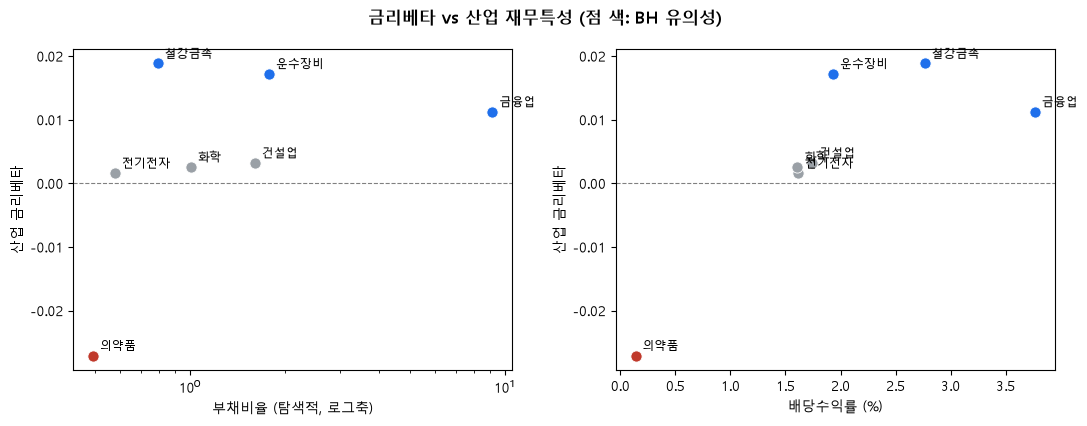

In [18]:
# 금리베타 vs 재무특성 산점도 (BH 유의성 기준 색상)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
panels = [("부채비율_시총가중", "부채비율 (탐색적, 로그축)", True), ("배당수익률_시총가중", "배당수익률 (%)", False)]
sig_map = beta_table.set_index("industry")["p_value_bh"].reindex(INDUSTRIES) < 0.05

for ax, (col, label, logx) in zip(axes, panels):
    for ind in INDUSTRIES:
        x, y = char.loc[ind, col], beta.loc[ind]
        color = (NEG_COLOR if y < 0 else POS_COLOR) if sig_map.loc[ind] else NS_COLOR
        ax.scatter(x, y, s=65, color=color, edgecolor="white", linewidth=0.6, zorder=3)
        ax.annotate(ind, (x, y), fontsize=8.5, xytext=(5, 4), textcoords="offset points")
    ax.axhline(0, color="gray", lw=0.8, ls="--")
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(label)
    ax.set_ylabel("산업 금리베타")
fig.suptitle("금리베타 vs 산업 재무특성 (점 색: BH 유의성)", fontweight="bold")
fig.tight_layout()
plt.show()

In [19]:
# 시가총액가중 결과가 소수 대형주에 얼마나 좌우되는지 확인한다.
def concentration(group):
    group = group.dropna(subset=["market_cap_2024"]).sort_values(
        "market_cap_2024", ascending=False
    ).reset_index(drop=True)
    total = group["market_cap_2024"].sum()
    share = group["market_cap_2024"] / total * 100
    hhi = float(((group["market_cap_2024"] / total) ** 2).sum())
    n = len(group)
    return {
        "top1_share_pct": share.iloc[0] if n >= 1 else np.nan,
        "top3_share_pct": share.iloc[:3].sum() if n >= 3 else np.nan,
        "hhi": hhi,
        "n_firms": n,
    }


pharma_summary = concentration(sel[sel["industry"] == "의약품"][["market_cap_2024"]].copy())
sup = pd.read_csv(config.PROCESSED_DIR / "pharma_rnd_support.csv").dropna(subset=["rnd_to_sales_pct"])
print(
    f"의약품 시총 집중도: Top1 {pharma_summary['top1_share_pct']:.1f}% · "
    f"Top3 {pharma_summary['top3_share_pct']:.1f}% · HHI {pharma_summary['hhi']:.3f}"
)
print(
    f"의약품 R&D/매출 중앙값: {sup['rnd_to_sales_pct'].median():.1f}% "
    f"({len(sup)}개사 전체, 회계기준 혼재)"
)


의약품 시총 집중도: Top1 50.6% · Top3 88.3% · HHI 0.357
의약품 R&D/매출 중앙값: 11.6% (10개사 전체, 회계기준 혼재)


의약품의 2024년 시가총액 집중도는 Top1 50.6%, Top3 88.3%, HHI 0.357이다. 시총가중 배당수익률은 소수 대형주의 영향이 크다.

R&D/매출 중앙값은 **10개사 전체 기준 약 11.6%**다.¹ 사업보고서 연구개발비 총계와 DART 경상연구개발비가 혼재하므로 이 값은 기업 간 강도 비교나 duration의 직접 측정치로 사용하지 않는다.

¹ 사전적 제외 기준이 없어 10개사를 모두 포함했다.

## 만기 구조와의 대조

| 설명변수 | 의약품 계수 | p-value |
|---|---:|---:|
| 국고 3년 | −0.02707 | 0.000548 |
| 국고 10년 | −0.01598 | 0.0697 |
| NS Level | −0.01382 | 0.383 |
| NS Slope | −0.00901 | 0.534 |
| NS Curvature | −0.00860 | 0.00236 |

장기금리와 Level 반응은 5% 수준에 도달하지 않았다. 이는 duration 해석을 기각하는 직접 검정은 아니지만, 의약품의 음(-) 베타를 duration 하나로 설명하지 않아야 하는 반대증거다.


# 5. 종합 결과와 해석 범위

| 단계 | 질문 | 핵심 결과 | 해석 범위 |
|---|---|---|---|
| Baseline | 산업별 3년 금리베타가 같은가? | 동일성 기각 | 조건부 관련성 |
| H1 | 어느 곡선요인에서 차이가 나타나는가? | $\lambda=0.5$ Curvature에서 관찰 | $\lambda$와 공통변동에 민감 |
| H2 | 상승·하락 계수가 같은가? | 건설업에서만 BH 유의 | 전 산업 검정은 경계적 |
| H3 | 재무특성과 베타가 정렬되는가? | 배당은 일부 사양에서 정렬, 부채는 안정적 관계 미확인 | n=7 탐색적 결과 |

### 데이터가 직접 보여주는 것

- **산업별 3년 금리베타의 동일성은 기각되었다.**
- Curvature의 산업 간 차이는 $\lambda=0.5$에서 관찰되지만 Level·Slope·Credit Spread에서는 확인되지 않았다.
- 건설업의 3년물 상승·하락 계수는 서로 달랐고 Curvature 방향분해는 비유의였다.
- 배당수익률은 시가총액가중에서 순위정렬이 관찰됐지만 중앙값에서 약해졌다. 부채비율은 주요 사양에서 안정적 관계가 확인되지 않았다.

### 경제적으로 가능한 해석

의약품의 음(-) 금리베타, 낮은 배당수익률, R&D 지출은 미래 현금흐름 비중이 큰 기업에 대한 이론과 모순되지 않는다. 건설업의 방향별 반응은 자금조달 민감 가능성과 정합적일 수 있다. 두 해석 모두 본 분석이 직접 검정한 인과경로는 아니다.

### 이 연구만으로 확정할 수 없는 것

- 관측 금리변화에서 순수 정책충격과 경기·물가 정보효과를 분리하지 않았다.
- **대체 $\lambda$에서는 Curvature 산업 차이가 5% 수준에서 유지되지 않았다.**
- H2 전 산업 동시검정은 p=0.040이며, 두 요인 전체를 하나의 다중검정족으로 묶으면 판단이 약해진다.
- H3는 n=7 산업 집계량에 기초하며 duration과 인과관계를 직접 측정하지 않는다.


# Appendix

## A. Baseline 강건성

### 21개 쌍별 비교와 표준오차 방식

공동검정이 유의해도 어느 산업쌍이 다른지는 알 수 없다. 7개 산업의 21개 조합을 모두 비교하고, HAC와 날짜 클러스터 표준오차 각각에 BH 보정을 적용한다.


In [20]:
# 통합 회귀를 HAC와 날짜 클러스터 표준오차로 각각 추정한다.
baseline_long = panel[["date", "industry", "industry_return", "kospi_return", "d_y3"]].dropna()
baseline_formula = "industry_return ~ 0 + C(industry) + C(industry):kospi_return + C(industry):d_y3"
pooled_hac = smf.ols(baseline_formula, data=baseline_long).fit(
    cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS}
)
date_codes = pd.factorize(baseline_long["date"])[0]
pooled_cluster = smf.ols(baseline_formula, data=baseline_long).fit(
    cov_type="cluster", cov_kwds={"groups": date_codes}
)


def rate_param(industry):
    return f"C(industry)[{industry}]:d_y3"


param_names = list(pooled_hac.params.index)
pairwise_rows = []
for industry_a, industry_b in combinations(industries, 2):
    contrast = np.zeros(len(param_names))
    contrast[param_names.index(rate_param(industry_a))] = 1.0
    contrast[param_names.index(rate_param(industry_b))] = -1.0
    test_hac = pooled_hac.t_test(contrast)
    test_cluster = pooled_cluster.t_test(contrast)
    pairwise_rows.append({
        "industry_a": industry_a,
        "industry_b": industry_b,
        "beta_difference": float(np.asarray(test_hac.effect).squeeze()),
        "p_value_hac": float(np.asarray(test_hac.pvalue).squeeze()),
        "p_value_cluster": float(np.asarray(test_cluster.pvalue).squeeze()),
    })

pairwise_table = pd.DataFrame(pairwise_rows)
pairwise_table["BH p-value (HAC)"] = multipletests(
    pairwise_table["p_value_hac"], method="fdr_bh"
)[1]
pairwise_table["BH p-value (날짜 클러스터)"] = multipletests(
    pairwise_table["p_value_cluster"], method="fdr_bh"
)[1]
pairwise_table["유의 (HAC)"] = pairwise_table["BH p-value (HAC)"] < 0.05
pairwise_table["유의 (날짜 클러스터)"] = pairwise_table["BH p-value (날짜 클러스터)"] < 0.05
pairwise_table = pairwise_table.sort_values("BH p-value (날짜 클러스터)").reset_index(drop=True)

print(
    "BH 5% 유의 쌍 — HAC:", int(pairwise_table["유의 (HAC)"].sum()),
    "/ 21 · 날짜 클러스터:", int(pairwise_table["유의 (날짜 클러스터)"].sum()), "/ 21"
)
pairwise_table.round(5)


BH 5% 유의 쌍 — HAC: 6 / 21 · 날짜 클러스터: 6 / 21


,industry_a,industry_b,beta_difference,p_value_hac,p_value_cluster,BH p-value (HAC),BH p-value (날짜 클러스터),유의 (HAC),유의 (날짜 클러스터)
0,금융업,의약품,0.03830,0.00002,0.00002,0.00018,0.00025,True,True
1,운수장비,의약품,0.04430,0.00001,0.00001,0.00018,0.00025,True,True
2,의약품,철강금속,-0.04590,0.00004,0.00006,0.00030,0.00045,True,True
3,의약품,화학,-0.02962,0.00118,0.00142,0.00620,0.00745,True,True
4,의약품,전기전자,-0.02865,0.00188,0.00212,0.00790,0.00892,True,True
5,건설업,의약품,0.03027,0.00449,0.00514,0.01571,0.01798,True,True
6,운수장비,화학,0.01467,0.04080,0.03071,0.10711,0.08061,False,False
7,철강금속,화학,0.01628,0.03337,0.02747,0.10011,0.08061,False,False
8,전기전자,철강금속,-0.01725,0.07274,0.07860,0.15275,0.15006,False,False
9,운수장비,전기전자,0.01564,0.05698,0.07171,0.13295,0.15006,False,False


두 표준오차 방식에서 BH 5% 유의 쌍은 같은 여섯 쌍이며 모두 의약품을 포함한다. 쌍별 비교의 판정은 표준오차 방식에 따라 바뀌지 않았다.


In [21]:
# 동일한 여섯 개 제약으로 공동검정의 HAC·날짜 클러스터 결과를 비교한다.
reference = industries[0]
R = []
for industry in industries[1:]:
    restriction = np.zeros(len(param_names))
    restriction[param_names.index(rate_param(reference))] = 1.0
    restriction[param_names.index(rate_param(industry))] = -1.0
    R.append(restriction)
R = np.vstack(R)

joint_hac = pooled_hac.f_test(R)
joint_cluster_appendix = pooled_cluster.f_test(R)
se_comparison = pd.DataFrame([
    {
        "표준오차 방식": f"HAC (lag={HAC_LAGS})",
        "F": float(joint_hac.fvalue),
        "p-value": float(joint_hac.pvalue),
        "5% 판정": "기각" if float(joint_hac.pvalue) < 0.05 else "기각 못함",
    },
    {
        "표준오차 방식": "날짜 클러스터",
        "F": float(joint_cluster_appendix.fvalue),
        "p-value": float(joint_cluster_appendix.pvalue),
        "5% 판정": "기각" if float(joint_cluster_appendix.pvalue) < 0.05 else "기각 못함",
    },
])
se_comparison.round(6)


,표준오차 방식,F,p-value,5% 판정
0,HAC (lag=5),4.269420,0.000264,기각
1,날짜 클러스터,4.189156,0.000338,기각


## B. H1 민감도와 기술적 진단

### $\lambda$ 설정에 따른 결과 변화

**확인할 문제.** Curvature 결과가 $\lambda$ 설정에 의존하는가?


In [22]:
# lambda 민감도 — 개별 산업의 3요인 동시유의성(own-joint) p값이 lambda에 얼마나 안정적인가
MATURITIES = np.array([1.0, 3.0, 5.0, 10.0])


def nelson_siegel_loadings(maturities, lambda_value):
    level = np.ones_like(maturities)
    slope_loading = (1.0 - np.exp(-lambda_value * maturities)) / (lambda_value * maturities)
    curvature_loading = slope_loading - np.exp(-lambda_value * maturities)
    return np.column_stack([level, slope_loading, curvature_loading])


# lambda별 요인 변화(diff)는 국고채 원자료 고유의 날짜(2,462일)를 기준으로 계산해야 한다.
# extended_panel(산업 패널과 병합 후 2,452일)에서 다시 만들면, 병합 과정에서 빠진 날짜
# 바로 다음 거래일의 diff가 실제보다 넓은 간격으로 계산되어 값이 미세하게 달라진다.
_yield_raw = pd.read_csv(config.RAW_YIELD_CURVE_FILE, encoding="utf-8-sig")
_maturity_map = {"국고채(1년)": "y1", "국고채(3년)": "y3_new", "국고채(5년)": "y5", "국고채(10년)": "y10_new"}
_yield_selected = _yield_raw[_yield_raw["계정항목"].isin(_maturity_map.keys())].copy()
_yield_selected["maturity_name"] = _yield_selected["계정항목"].map(_maturity_map)
_meta_cols = [c for c in ["통계표", "계정항목", "단위", "변환"] if c in _yield_selected.columns]
_date_cols = [c for c in _yield_selected.columns if c not in _meta_cols + ["maturity_name"]]
_yield_long = _yield_selected.melt(id_vars=["maturity_name"], value_vars=_date_cols, var_name="date", value_name="yield")
_yield_long["date"] = pd.to_datetime(_yield_long["date"], errors="coerce")
_yield_long["yield"] = pd.to_numeric(_yield_long["yield"], errors="coerce")
yield_wide = (
    _yield_long.pivot(index="date", columns="maturity_name", values="yield")
    .reset_index().sort_values("date").dropna().reset_index(drop=True)
)
yield_wide.columns.name = None
yield_wide = yield_wide[["date", "y1", "y3_new", "y5", "y10_new"]]
yield_matrix = yield_wide[["y1", "y3_new", "y5", "y10_new"]].to_numpy(dtype=float)

# 검증: lambda=0.5에서 이렇게 재구성한 d_ns_curvature가 본문 lambda=0.5 변수과 정확히 일치하는지 확인
_chk_X = nelson_siegel_loadings(MATURITIES, config.NS_LAMBDA)
_chk_betas = yield_matrix @ np.linalg.pinv(_chk_X).T
_chk = pd.DataFrame({"date": yield_wide["date"], "d_C_chk": _chk_betas[:, 2]})
_chk["d_C_chk"] = _chk["d_C_chk"].diff()
_chk_merge = _chk.merge(extended_panel[["date", "d_ns_curvature"]].drop_duplicates("date"), on="date", how="inner")
_max_diff = (_chk_merge["d_C_chk"] - _chk_merge["d_ns_curvature"]).abs().max()
print(f"검증: 원자료 기준 재구성 d_ns_curvature vs 본문 lambda=0.5 변수, 최대 절대차 = {_max_diff:.2e}")

LAMBDA_GRID = [0.2, 0.3, 0.4, 0.5, 0.6, config.NS_LAMBDA_COMPARE, 1.0, 1.5, 2.0]


def lambda_case(lam):
    X = nelson_siegel_loadings(MATURITIES, lam)
    B = yield_matrix @ np.linalg.pinv(X).T
    f = pd.DataFrame(B, index=yield_wide["date"], columns=["L", "S", "C"]).diff().dropna()
    f.columns = ["d_L", "d_S", "d_C"]
    f = f.reset_index()
    dd = extended_panel[["date", "industry", "industry_return", "kospi_return"]].merge(f, on="date", how="inner")
    joint = {}
    for ind, g in dd.groupby("industry"):
        z = g[["industry_return", "kospi_return", "d_L", "d_S", "d_C"]].dropna()
        m = sm.OLS(z["industry_return"], sm.add_constant(z[["kospi_return", "d_L", "d_S", "d_C"]], has_constant="add")
                   ).fit(cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS})
        joint[ind] = float(m.f_test("d_L = 0, d_S = 0, d_C = 0").pvalue)
    return {"lambda": lam, "동시검정_유의산업수": int(sum(v < 0.05 for v in joint.values())),
            "의약품_p": round(joint.get("의약품", np.nan), 5), "운수장비_p": round(joint.get("운수장비", np.nan), 5)}


lambda_sensitivity = pd.DataFrame([lambda_case(l) for l in LAMBDA_GRID])
lambda_sensitivity

검증: 원자료 기준 재구성 d_ns_curvature vs 본문 lambda=0.5 변수, 최대 절대차 = 9.89e-17


,lambda,동시검정_유의산업수,의약품_p,운수장비_p
0,0.2000,3,0.00440,0.01317
1,0.3000,3,0.00371,0.01310
2,0.4000,3,0.00314,0.01309
3,0.5000,3,0.00268,0.01313
4,0.6000,3,0.00232,0.01322
5,0.8041,3,0.00181,0.01348
6,1.0000,3,0.00151,0.01376
7,1.5000,3,0.00117,0.01434
8,2.0000,3,0.00106,0.01463


$\lambda=0.2$~2.0에서 개별 산업의 3요인 동시검정 결과를 먼저 확인한다. 이 검정은 산업 자신의 세 계수가 모두 0인지 묻는 것으로, 산업 간 Curvature 동일성 검정과는 다른 질문이다.


In [23]:
# Curvature 산업 간 차이 검정의 lambda 민감도 (본문 검정을 lambda 그리드 전체로 확장)
def industry_difference_by_lambda(lam):
    X = nelson_siegel_loadings(MATURITIES, lam)
    B = yield_matrix @ np.linalg.pinv(X).T
    f = pd.DataFrame(B, index=yield_wide["date"], columns=["L", "S", "C"]).diff().dropna()
    f.columns = ["d_L", "d_S", "d_C"]
    f = f.reset_index()
    dd = extended_panel[["date", "industry", "industry_return", "kospi_return"]].merge(f, on="date", how="inner")
    r = run_industry_difference_test(dd, ["d_L", "d_S", "d_C"], "lambda_grid")
    r["p_value_bh"] = multipletests(r["p_value"], method="fdr_bh")[1]
    return {"lambda": lam, "F_curvature": r.loc[r["variable"] == "d_C", "f_stat"].iloc[0],
            "BH_p_curvature": r.loc[r["variable"] == "d_C", "p_value_bh"].iloc[0]}


lambda_diff_sensitivity = pd.DataFrame([industry_difference_by_lambda(l) for l in LAMBDA_GRID])
lambda_diff_sensitivity.round(4)

,lambda,F_curvature,BH_p_curvature
0,0.2000,1.4090,0.2072
1,0.3000,3.0799,0.0158
2,0.4000,3.9124,0.0020
3,0.5000,3.5800,0.0047
4,0.6000,3.0786,0.0158
5,0.8041,2.2866,0.0998
6,1.0000,1.8091,0.2804
7,1.5000,1.2489,0.4171
8,2.0000,1.0679,0.4489


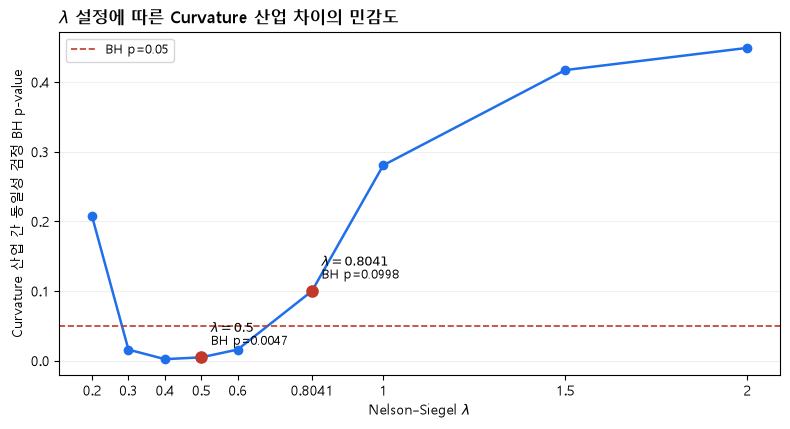

In [24]:
# 기존 lambda 격자 결과를 그림으로 표시한다.
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(
    lambda_diff_sensitivity["lambda"],
    lambda_diff_sensitivity["BH_p_curvature"],
    color=POS_COLOR,
    marker="o",
    linewidth=1.8,
)
ax.axhline(0.05, color=NEG_COLOR, linestyle="--", linewidth=1.2, label="BH p=0.05")

highlight_specs = [(0.5, "$\\lambda=0.5$"), (config.NS_LAMBDA_COMPARE, "$\\lambda=0.8041$")]
for lam, label in highlight_specs:
    point = lambda_diff_sensitivity.loc[
        np.isclose(lambda_diff_sensitivity["lambda"], lam)
    ].iloc[0]
    ax.scatter(point["lambda"], point["BH_p_curvature"], s=65, color=NEG_COLOR, zorder=4)
    ax.annotate(
        f"{label}\nBH p={point['BH_p_curvature']:.4f}",
        (point["lambda"], point["BH_p_curvature"]),
        xytext=(7, 9),
        textcoords="offset points",
        fontsize=9,
    )

ax.set_xticks(lambda_diff_sensitivity["lambda"])
ax.set_xticklabels([f"{x:g}" for x in lambda_diff_sensitivity["lambda"]])
ax.set_xlabel("Nelson–Siegel $\\lambda$")
ax.set_ylabel("Curvature 산업 간 동일성 검정 BH p-value")
ax.set_title("$\\lambda$ 설정에 따른 Curvature 산업 차이의 민감도", loc="left", fontweight="bold")
ax.legend(frameon=True, fontsize=9)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()


**판단.** 산업 간 Curvature 차이는 $\lambda=0.3$~0.6에서만 5% 수준에 도달했다. 곡선 재구성 오차가 가장 작은 $\lambda=0.8041$에서는 BH p=0.0998이다. 결과는 전체 격자에서 안정적이지 않다.


In [25]:
# PCA 전체 적재값
YIELD_CHANGE_COLS = ["d_y1", "d_y3_new", "d_y5", "d_y10_new"]
MATURITY_LABELS = ["1년", "3년", "5년", "10년"]
Z = yield_changes[YIELD_CHANGE_COLS].to_numpy(dtype=float)
Zc = Z - Z.mean(axis=0)
eigval, eigvec = np.linalg.eigh(np.cov(Zc, rowvar=False))
order = np.argsort(eigval)[::-1]
eigval, eigvec = eigval[order], eigvec[:, order]
explained = eigval / eigval.sum()

pca_table = pd.DataFrame({
    "component": [f"PC{i+1}" for i in range(len(eigval))],
    "explained_ratio": explained,
    "cumulative_ratio": np.cumsum(explained),
})
for j, label in enumerate(MATURITY_LABELS):
    pca_table[f"loading_{label}"] = eigvec[j, :]
pca_table.round(4)

,component,explained_ratio,cumulative_ratio,loading_1년,loading_3년,loading_5년,loading_10년
0,PC1,0.9209,0.9209,-0.2363,-0.5334,-0.5849,-0.5635
1,PC2,0.0479,0.9688,-0.4581,-0.5357,-0.0096,0.7092
2,PC3,0.0224,0.9912,-0.8526,0.3826,0.2446,-0.2585
3,PC4,0.0088,1.0000,-0.0853,0.5311,-0.7733,0.3356


In [26]:
# VIF·요인 상관행렬
VIF_VARS = ["kospi_return", "d_ns_level", "d_ns_slope", "d_ns_curvature", "d_credit_spread"]
factor_daily = extended_panel[["date"] + VIF_VARS].drop_duplicates(subset="date").dropna()
vif_design = sm.add_constant(factor_daily[VIF_VARS], has_constant="add")
vif_values = {
    var: variance_inflation_factor(vif_design.to_numpy(dtype=float), i)
    for i, var in enumerate(vif_design.columns) if var != "const"
}
pd.Series(vif_values, name="VIF").round(3).to_frame()

,VIF
kospi_return,1.006
d_ns_level,7.254
d_ns_slope,7.014
d_ns_curvature,2.447
d_credit_spread,1.228


PC1 적재량과 VIF는 요인들의 공통변동을 확인하는 진단이다. Level과 Slope의 VIF는 각각 약 7.25와 7.01이며 상관은 −0.843이다. Curvature와 Credit Spread의 VIF는 더 낮지만, 이 값만으로 두 변수의 경제적 효과를 분리할 수는 없다.


In [27]:
# Gram–Schmidt 직교화와 FWL 검증
def orthogonalize_factors(daily, factor_cols):
    out = daily.copy()
    built = []
    for col in factor_cols:
        target = f"o_{col}"
        if not built:
            out[target] = out[col]
        else:
            X = sm.add_constant(out[built], has_constant="add")
            out[target] = sm.OLS(out[col], X).fit().resid
        built.append(target)
    return out, built


base_factors = ["d_ns_level", "d_ns_slope", "d_ns_curvature"]
orth_daily, orth_cols = orthogonalize_factors(
    extended_panel[["date"] + base_factors].drop_duplicates("date").dropna(),
    base_factors,
)
orth_panel = extended_panel.merge(
    orth_daily[["date"] + orth_cols], on="date", how="left", validate="many_to_one"
)
orth_betas = run_yield_curve_factor_model(
    orth_panel,
    x_cols=["kospi_return"] + orth_cols,
    factor_labels={
        "o_d_ns_level": "Level_orth",
        "o_d_ns_slope": "Slope_orth",
        "o_d_ns_curvature": "Curvature_orth",
    },
)
fwl_check = (
    yield_curve_factor_betas[yield_curve_factor_betas["factor"] == "Curvature"]
    [["industry", "coefficient", "std_error_hac", "p_value"]]
    .rename(columns={
        "coefficient": "coef_3factor",
        "std_error_hac": "se_3factor",
        "p_value": "p_3factor",
    })
    .merge(
        orth_betas[orth_betas["factor"] == "Curvature_orth"]
        [["industry", "coefficient", "std_error_hac", "p_value"]]
        .rename(columns={
            "coefficient": "coef_orth",
            "std_error_hac": "se_orth",
            "p_value": "p_orth",
        }),
        on="industry",
        validate="one_to_one",
    )
)
fwl_check["계수 절대차"] = (fwl_check["coef_3factor"] - fwl_check["coef_orth"]).abs()
fwl_check["SE 절대차"] = (fwl_check["se_3factor"] - fwl_check["se_orth"]).abs()
print("직교화 후 최대 요인상관:", orth_daily[orth_cols].corr().where(
    ~np.eye(len(orth_cols), dtype=bool)
).abs().max().max())
print("FWL 계수·SE 최대 절대차:", fwl_check[["계수 절대차", "SE 절대차"]].to_numpy().max())
fwl_check.round(8)


직교화 후 최대 요인상관: 1.2336772916561571e-15
FWL 계수·SE 최대 절대차: 1.2815269678778662e-16


,industry,coef_3factor,se_3factor,p_3factor,coef_orth,se_orth,p_orth,계수 절대차,SE 절대차
0,건설업,-0.002338,0.003058,0.444568,-0.002338,0.003058,0.444568,0.0,0.0
1,금융업,0.002413,0.001370,0.078067,0.002413,0.001370,0.078067,0.0,0.0
2,운수장비,0.006207,0.002310,0.007206,0.006207,0.002310,0.007206,0.0,0.0
3,의약품,-0.008599,0.002828,0.002363,-0.008599,0.002828,0.002363,0.0,0.0
4,전기전자,0.001441,0.001582,0.362277,0.001441,0.001582,0.362277,0.0,0.0
5,철강금속,0.004148,0.002878,0.149483,0.004148,0.002878,0.149483,0.0,0.0
6,화학,-0.000080,0.001704,0.962436,-0.000080,0.001704,0.962436,0.0,0.0


**판단.** 마지막에 직교화한 Curvature의 계수와 표준오차는 원래 3요인 모형과 수치오차 범위에서 같다. 이는 FWL 정리의 기계적 결과다. 직교화는 공유변동을 앞 요인에 배정하며 순서에 의존하므로 강건한 인과증거로 사용하지 않는다.


In [28]:
# Curvature와 Credit Spread의 공유변동 및 FWL 성질
credit_daily = (
    extended_panel[["date", "kospi_return", "d_ns_level", "d_ns_slope",
                    "d_ns_curvature", "d_credit_spread"]]
    .drop_duplicates("date").dropna().reset_index(drop=True)
)
credit_X = sm.add_constant(
    credit_daily[["kospi_return", "d_ns_level", "d_ns_slope", "d_ns_curvature"]],
    has_constant="add",
)
credit_projection = sm.OLS(credit_daily["d_credit_spread"], credit_X).fit()
credit_daily["d_credit_orth"] = credit_projection.resid
credit_orth_panel = extended_panel.merge(
    credit_daily[["date", "d_credit_orth"]], on="date", how="left", validate="many_to_one"
)
credit_orth_betas = run_yield_curve_factor_model(
    credit_orth_panel,
    x_cols=["kospi_return", "d_ns_level", "d_ns_slope", "d_ns_curvature", "d_credit_orth"],
    factor_labels={
        "d_ns_level": "Level",
        "d_ns_slope": "Slope",
        "d_ns_curvature": "Curvature",
        "d_credit_orth": "CreditSpread_orth",
    },
)
credit_fwl = (
    yield_curve_factor_betas[yield_curve_factor_betas["factor"] == "Curvature"]
    [["industry", "coefficient"]]
    .rename(columns={"coefficient": "coef_3factor"})
    .merge(
        credit_orth_betas[credit_orth_betas["factor"] == "Curvature"]
        [["industry", "coefficient"]]
        .rename(columns={"coefficient": "coef_credit_orth"}),
        on="industry",
        validate="one_to_one",
    )
)
credit_fwl["절대차"] = (credit_fwl["coef_3factor"] - credit_fwl["coef_credit_orth"]).abs()
print(f"Credit Spread가 시장·곡선 3요인과 공유하는 변동(R²): {credit_projection.rsquared:.4f}")
print(f"3요인 vs Credit 직교화 모형 Curvature 계수 최대 절대차: {credit_fwl['절대차'].max():.2e}")
credit_fwl.round(8)


Credit Spread가 시장·곡선 3요인과 공유하는 변동(R²): 0.1859
3요인 vs Credit 직교화 모형 Curvature 계수 최대 절대차: 8.30e-17


,industry,coef_3factor,coef_credit_orth,절대차
0,건설업,-0.002338,-0.002338,0.0
1,금융업,0.002413,0.002413,0.0
2,운수장비,0.006207,0.006207,0.0
3,의약품,-0.008599,-0.008599,0.0
4,전기전자,0.001441,0.001441,0.0
5,철강금속,0.004148,0.004148,0.0
6,화학,-0.000080,-0.000080,0.0


Credit Spread 변동의 약 18.6%가 시장수익률과 곡선요인으로 설명된다. 직교화 뒤 Curvature 계수가 보존되는 것은 FWL의 필연적 결과다. **이 진단은 Curvature의 산업 차이가 Credit Spread로 흡수되지 않는다는 주장까지 식별하지 않는다.**


In [29]:
# 20년·30년을 추가했을 때 곡선 적합도와 요인 분리가 개선되는지 재계산한다.
def yield_rows_to_wide(raw, item_map):
    selected = raw[raw["계정항목"].isin(item_map)].copy()
    selected["maturity"] = selected["계정항목"].map(item_map)
    meta = [c for c in ["통계표", "계정항목", "단위", "변환"] if c in selected.columns]
    date_cols = [c for c in selected.columns if c not in meta + ["maturity"]]
    long = selected.melt(
        id_vars=["maturity"], value_vars=date_cols, var_name="date", value_name="yield"
    )
    long["date"] = pd.to_datetime(long["date"], errors="coerce")
    long["yield"] = pd.to_numeric(long["yield"], errors="coerce")
    return long.pivot(index="date", columns="maturity", values="yield").sort_index()


base_raw = pd.read_csv(config.RAW_YIELD_CURVE_FILE, encoding="utf-8-sig")
extra_raw = pd.read_csv(
    config.RAW_DIR / "rates" / "treasury_yield_curve_extended.csv.csv",
    encoding="utf-8-sig",
)
base_wide = yield_rows_to_wide(base_raw, {
    "국고채(1년)": "y1", "국고채(3년)": "y3", "국고채(5년)": "y5", "국고채(10년)": "y10",
})
extra_wide = yield_rows_to_wide(extra_raw, {
    "국고채(20년)": "y20", "국고채(30년)": "y30",
})
curve_wide = base_wide.join(extra_wide, how="inner").dropna()


def maturity_set_diagnostic(columns, maturities):
    matrix = curve_wide[columns].to_numpy(dtype=float)

    def rmse(lambda_value):
        loadings = nelson_siegel_loadings(np.asarray(maturities, float), lambda_value)
        factors = matrix @ np.linalg.pinv(loadings).T
        return float(np.sqrt(np.mean((matrix - factors @ loadings.T) ** 2)))

    optimum = minimize_scalar(rmse, bounds=(0.05, 3.0), method="bounded")
    loadings = nelson_siegel_loadings(np.asarray(maturities, float), optimum.x)
    factors = matrix @ np.linalg.pinv(loadings).T
    changes = pd.DataFrame(factors, columns=["L", "S", "C"]).diff().dropna()
    design = sm.add_constant(changes, has_constant="add")
    max_vif = max(
        variance_inflation_factor(design.to_numpy(dtype=float), i)
        for i in range(1, design.shape[1])
    )
    eigenvalues = np.linalg.eigvalsh(np.cov(np.diff(matrix, axis=0), rowvar=False))[::-1]
    return {
        "관측일": len(matrix),
        "최적 lambda": optimum.x,
        "곡선 RMSE": optimum.fun,
        "최대 VIF": max_vif,
        "PC1 설명비중(%)": eigenvalues[0] / eigenvalues.sum() * 100,
    }


maturity_extension = pd.DataFrame([
    {"만기 세트": "1·3·5·10년", **maturity_set_diagnostic(["y1", "y3", "y5", "y10"], [1, 3, 5, 10])},
    {"만기 세트": "+20·30년", **maturity_set_diagnostic(["y1", "y3", "y5", "y10", "y20", "y30"], [1, 3, 5, 10, 20, 30])},
])
maturity_extension.round(4)


,만기 세트,관측일,최적 lambda,곡선 RMSE,최대 VIF,PC1 설명비중(%)
0,1·3·5·10년,2462,0.8041,0.0108,9.4592,92.0854
1,+20·30년,2462,1.1339,0.0384,18.3560,88.9208


**판단.** 20년·30년을 추가하면 최적 $\lambda$에서 곡선 RMSE가 약 3.5배 커지고 최대 VIF도 약 9.46에서 18.36으로 높아진다. 만기를 늘려도 요인 분리가 개선되지 않아 본분석의 만기 세트는 바꾸지 않는다.


In [30]:
# HAC lag 5·8·10·20에서 3요인·4요인 계수의 유의성 판정을 비교한다.
HAC_LAG_GRID = [5, 8, 10, 20]
hac_frames = []
for lag_value in HAC_LAG_GRID:
    three = run_yield_curve_factor_model(extended_panel, hac_lags=lag_value).assign(
        model="3요인", hac_lags=lag_value
    )
    four = run_yield_curve_factor_model(
        extended_panel,
        hac_lags=lag_value,
        x_cols=["kospi_return", "d_ns_level", "d_ns_slope", "d_ns_curvature", "d_credit_spread"],
        factor_labels={
            "d_ns_level": "Level",
            "d_ns_slope": "Slope",
            "d_ns_curvature": "Curvature",
            "d_credit_spread": "CreditSpread",
        },
    ).assign(model="4요인", hac_lags=lag_value)
    hac_frames.extend([three, four])

hac_sensitivity = pd.concat(hac_frames, ignore_index=True)
hac_sensitivity["significant_5pct"] = hac_sensitivity["p_value"] < 0.05
hac_flip = (
    hac_sensitivity.groupby(["model", "industry", "factor"])["significant_5pct"]
    .nunique().reset_index(name="판정 수")
)
hac_summary = (
    hac_sensitivity.groupby(["model", "hac_lags"])
    .agg(유의_조합=("significant_5pct", "sum"), 전체_조합=("significant_5pct", "size"))
    .reset_index()
)
print("lag에 따라 5% 판정이 바뀐 조합:", int((hac_flip["판정 수"] > 1).sum()))
hac_summary


lag에 따라 5% 판정이 바뀐 조합: 0


,model,hac_lags,유의_조합,전체_조합
0,3요인,5,3,21
1,3요인,8,3,21
2,3요인,10,3,21
3,3요인,20,3,21
4,4요인,5,3,28
5,4요인,8,3,28
6,4요인,10,3,28
7,4요인,20,3,28


HAC 시차는 계수를 바꾸지 않고 표준오차와 p-value를 바꾼다. 위 표와 판정 변화 수는 lag 선택에 따른 유의성 민감도를 직접 보여준다. 산업 간 동일성 검정은 날짜 클러스터 표준오차를 사용하므로 이 HAC lag 비교의 대상이 아니다.


## C. H2 강건성·민감도 분석

아래 강건성 결과는 본 노트북에서 다시 계산한다. `07_asymmetric_rate_response.ipynb`에서 산출·검증된 표는 수치 일치를 확인하는 기준으로만 사용한다.


In [31]:
# Curvature 상승·하락 계수 동일성의 산업별 Wald 검정
curvature_wald_tests.round(5)


,industry,f_stat,p_value,p_value_bh
0,건설업,0.52478,0.46888,0.78409
1,금융업,0.01180,0.91351,0.91351
2,운수장비,1.11124,0.29192,0.78409
3,의약품,0.07584,0.78304,0.91351
4,전기전자,0.33969,0.56006,0.78409
5,철강금속,2.49889,0.11406,0.78409
6,화학,0.47997,0.48850,0.78409


### 극단값과 기간 의존성

**확인할 문제.** 건설업 비대칭이 일부 급변동일이나 특정 기간에 의해 만들어졌는가?


In [32]:
# H2 강건성 사양을 live 재계산하고 07의 검증표와 대조한다.
h2_panel = extended_panel.copy()


def h2_industry_wald(data, up_col, down_col, model_name, include_direction_dummy=False):
    rows = []
    for industry in industries:
        use_cols = ["industry_return", "kospi_return", up_col, down_col]
        sample = data.loc[data["industry"] == industry, use_cols].replace(
            [np.inf, -np.inf], np.nan
        ).dropna().copy()
        x_cols = ["kospi_return", up_col, down_col]
        if include_direction_dummy:
            sample = sample[(sample[up_col] > 0) | (sample[down_col] < 0)].copy()
            sample["direction_up_dummy"] = (sample[up_col] > 0).astype(float)
            x_cols = ["kospi_return", "direction_up_dummy", up_col, down_col]

        X = sm.add_constant(sample[x_cols], has_constant="add")
        model = sm.OLS(sample["industry_return"], X).fit(
            cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS}
        )
        ci = model.conf_int(alpha=0.05)
        wald = model.f_test(f"{up_col} = {down_col}")
        rows.append({
            "model": model_name,
            "industry": industry,
            "beta_up": model.params[up_col],
            "se_up": model.bse[up_col],
            "ci_lower_up": ci.loc[up_col, 0],
            "ci_upper_up": ci.loc[up_col, 1],
            "p_up": model.pvalues[up_col],
            "beta_down": model.params[down_col],
            "se_down": model.bse[down_col],
            "ci_lower_down": ci.loc[down_col, 0],
            "ci_upper_down": ci.loc[down_col, 1],
            "p_down": model.pvalues[down_col],
            "beta_difference": model.params[up_col] - model.params[down_col],
            "f_stat": float(np.asarray(wald.fvalue).squeeze()),
            "p_value": float(np.asarray(wald.pvalue).squeeze()),
            "nobs": int(model.nobs),
            "r_squared": model.rsquared,
        })
    return add_bh_correction(pd.DataFrame(rows), group_cols=("model",))


def assert_h2_reference_match(live, filename, keys, numeric_cols, tolerance=1e-8):
    reference = pd.read_csv(config.H2_TABDIR / filename)
    left = live[keys + numeric_cols].copy()
    right = reference[keys + numeric_cols].copy()
    for key in keys:
        left[key] = left[key].astype(str)
        right[key] = right[key].astype(str)
    compared = left.merge(right, on=keys, suffixes=("_live", "_reference"), validate="one_to_one")
    if len(compared) != len(left) or len(compared) != len(right):
        raise AssertionError(f"{filename}: live 결과와 검증표의 행 구성이 다릅니다.")
    differences = []
    for col in numeric_cols:
        diff = (compared[f"{col}_live"] - compared[f"{col}_reference"]).abs().max()
        differences.append(0.0 if pd.isna(diff) else float(diff))
    max_diff = max(differences, default=0.0)
    if max_diff >= tolerance:
        raise AssertionError(f"{filename}: 최대 수치 차이 {max_diff:.3e}")
    print(f"검증표 대조 완료: {filename} · 최대 차이 {max_diff:.2e}")


def add_rate_split(data, source_col, prefix):
    out = data.copy()
    out[f"{prefix}_up"] = out[source_col].clip(lower=0)
    out[f"{prefix}_down"] = out[source_col].clip(upper=0)
    return out


def subset_h2_dates(data, start=None, end=None, exclude_start=None, exclude_end=None):
    out = data.copy()
    if start is not None:
        out = out[out["date"] >= pd.Timestamp(start)]
    if end is not None:
        out = out[out["date"] <= pd.Timestamp(end)]
    if exclude_start is not None and exclude_end is not None:
        excluded = out["date"].between(pd.Timestamp(exclude_start), pd.Timestamp(exclude_end))
        out = out[~excluded]
    return out.copy()


daily_abs = (
    h2_panel[["date", "d_y3"]].drop_duplicates("date").dropna()
    .assign(abs_d_y3=lambda frame: frame["d_y3"].abs())
)
q01, q99 = h2_panel["d_y3"].dropna().quantile([0.01, 0.99])
winsor_panel = add_rate_split(
    h2_panel.assign(d_y3_winsor_1pct=h2_panel["d_y3"].clip(q01, q99)),
    "d_y3_winsor_1pct",
    "d_y3_winsor_1pct",
)
abs_q99 = daily_abs["abs_d_y3"].quantile(0.99)
abs_q995 = daily_abs["abs_d_y3"].quantile(0.995)

extreme_specs = {
    "baseline": (h2_panel, "d_y3_up", "d_y3_down"),
    "winsor_1pct": (winsor_panel, "d_y3_winsor_1pct_up", "d_y3_winsor_1pct_down"),
    "trim_abs_top_1pct": (
        h2_panel[~h2_panel["date"].isin(daily_abs.loc[daily_abs["abs_d_y3"] > abs_q99, "date"])],
        "d_y3_up", "d_y3_down",
    ),
    "trim_abs_top_0_5pct": (
        h2_panel[~h2_panel["date"].isin(daily_abs.loc[daily_abs["abs_d_y3"] > abs_q995, "date"])],
        "d_y3_up", "d_y3_down",
    ),
}
extreme_parts = []
for specification, (data, up_col, down_col) in extreme_specs.items():
    result = h2_industry_wald(data, up_col, down_col, specification)
    result["specification"] = specification
    extreme_parts.append(result)
extreme_all = pd.concat(extreme_parts, ignore_index=True)
extreme_construction = extreme_all[extreme_all["industry"] == "건설업"].copy()

period_specs = {
    "full_2016_2025": h2_panel,
    "split_2016_2020": subset_h2_dates(h2_panel, "2016-01-01", "2020-12-31"),
    "split_2021_2025": subset_h2_dates(h2_panel, "2021-01-01", "2025-12-31"),
    "period_2016_2019": subset_h2_dates(h2_panel, "2016-01-01", "2019-12-31"),
    "period_2020_2021": subset_h2_dates(h2_panel, "2020-01-01", "2021-12-31"),
    "period_2022_2025": subset_h2_dates(h2_panel, "2022-01-01", "2025-12-31"),
    "exclude_2020_2021": subset_h2_dates(h2_panel, exclude_start="2020-01-01", exclude_end="2021-12-31"),
    "exclude_2022_2023": subset_h2_dates(h2_panel, exclude_start="2022-01-01", exclude_end="2023-12-31"),
}
period_parts = []
for specification, data in period_specs.items():
    result = h2_industry_wald(data, "d_y3_up", "d_y3_down", specification)
    result["specification"] = specification
    period_parts.append(result)
period_all = pd.concat(period_parts, ignore_index=True)
period_construction = period_all[period_all["industry"] == "건설업"].copy()

nonzero_panel = h2_panel[(h2_panel["d_y3_up"] > 0) | (h2_panel["d_y3_down"] < 0)].copy()
direction_parts = [
    h2_industry_wald(h2_panel, "d_y3_up", "d_y3_down", "baseline_full"),
    h2_industry_wald(nonzero_panel, "d_y3_up", "d_y3_down", "nonzero_no_dummy"),
    h2_industry_wald(
        nonzero_panel, "d_y3_up", "d_y3_down", "nonzero_with_up_dummy",
        include_direction_dummy=True,
    ),
]
direction_all = pd.concat(direction_parts, ignore_index=True)
direction_all["specification"] = direction_all["model"]
direction_construction = direction_all[direction_all["industry"] == "건설업"].copy()

master_parts = []
for category, part in [
    ("extreme_value", extreme_construction),
    ("period", period_construction),
    ("direction_intercept", direction_construction),
]:
    selected = part[["specification", "beta_up", "beta_down", "f_stat", "p_value", "p_value_bh", "nobs"]].copy()
    selected.insert(0, "category", category)
    master_parts.append(selected)
construction_robustness = pd.concat(master_parts, ignore_index=True)
construction_robustness["robust_bh5"] = construction_robustness["p_value_bh"] < 0.05

assert_h2_reference_match(
    construction_robustness,
    "robustness_construction_master.csv",
    ["category", "specification"],
    ["beta_up", "beta_down", "f_stat", "p_value", "p_value_bh", "nobs"],
)

spec_labels = {
    "baseline": "기준 사양", "baseline_full": "기준 사양",
    "trim_abs_top_0_5pct": "절대변화 상위 0.5% 제거",
    "trim_abs_top_1pct": "절대변화 상위 1% 제거",
    "winsor_1pct": "1%/99% Winsorize",
    "exclude_2020_2021": "2020–2021 제외", "exclude_2022_2023": "2022–2023 제외",
    "full_2016_2025": "2016–2025 전체", "period_2016_2019": "2016–2019",
    "period_2020_2021": "2020–2021", "period_2022_2025": "2022–2025",
    "split_2016_2020": "2016–2020 분할", "split_2021_2025": "2021–2025 분할",
    "nonzero_no_dummy": "무변화일 제외", "nonzero_with_up_dummy": "상승일 절편 추가",
}
category_labels = {"extreme_value": "극단값", "period": "기간", "direction_intercept": "절편 사양"}
construction_robustness["사양"] = construction_robustness["specification"].map(spec_labels)
construction_robustness["구분"] = construction_robustness["category"].map(category_labels)
construction_robustness[[
    "구분", "사양", "beta_up", "beta_down", "f_stat", "p_value_bh", "nobs", "robust_bh5"
]].round(4)


검증표 대조 완료: robustness_construction_master.csv · 최대 차이 1.78e-15


,구분,사양,beta_up,beta_down,f_stat,p_value_bh,nobs,robust_bh5
0,극단값,기준 사양,-0.0216,0.0310,10.4178,0.0089,2451,True
1,극단값,1%/99% Winsorize,-0.0215,0.0395,7.7450,0.0380,2451,True
2,극단값,절대변화 상위 1% 제거,-0.0090,0.0369,3.7392,0.1864,2426,False
3,극단값,절대변화 상위 0.5% 제거,-0.0168,0.0379,5.4182,0.1401,2438,False
4,기간,2016–2025 전체,-0.0216,0.0310,10.4178,0.0089,2451,True
5,기간,2016–2020 분할,0.0168,0.0386,0.2286,0.7651,1226,False
6,기간,2021–2025 분할,-0.0355,0.0267,11.1433,0.0061,1225,True
7,기간,2016–2019,0.0353,0.0675,0.4010,0.7826,978,False
8,기간,2020–2021,-0.0198,-0.0011,0.1340,0.7720,496,False
9,기간,2022–2025,-0.0387,0.0251,10.0713,0.0109,977,True


**판단.** 부호 패턴은 여러 사양에서 유지되지만 상위 0.5%·1% 제거, 일부 기간 제외와 초기 기간 분할에서는 BH 5% 기준을 넘지 못한다. 건설업 결과는 일부 급변동일과 최근 기간에 민감할 수 있다.


In [33]:
# 급변동일 한 날짜씩 제외한 결과와 3년 Rolling Window 결과를 live 재계산한다.
top_extreme_dates = daily_abs.nlargest(10, "abs_d_y3")[["date", "d_y3", "abs_d_y3"]]
leave_one_out_rows = []
for _, extreme_day in top_extreme_dates.iterrows():
    result = h2_industry_wald(
        h2_panel[h2_panel["date"] != extreme_day["date"]],
        "d_y3_up", "d_y3_down", f"drop_{extreme_day['date'].date()}",
    )
    construction = result[result["industry"] == "건설업"].iloc[0]
    leave_one_out_rows.append({
        "excluded_date": extreme_day["date"].strftime("%Y-%m-%d"),
        "excluded_d_y3": extreme_day["d_y3"],
        "excluded_abs_d_y3": extreme_day["abs_d_y3"],
        "beta_up": construction["beta_up"], "beta_down": construction["beta_down"],
        "f_stat": construction["f_stat"], "p_value": construction["p_value"],
        "p_value_bh": construction["p_value_bh"], "nobs": construction["nobs"],
    })
extreme_date_loo = pd.DataFrame(leave_one_out_rows)

rolling_rows = []
min_year, max_year, window_years = int(h2_panel["date"].dt.year.min()), int(h2_panel["date"].dt.year.max()), 3
for start_year in range(min_year, max_year - window_years + 2):
    end_year = start_year + window_years - 1
    rolling_data = subset_h2_dates(
        h2_panel, start=f"{start_year}-01-01", end=f"{end_year}-12-31"
    )
    result = h2_industry_wald(
        rolling_data, "d_y3_up", "d_y3_down", f"rolling_{start_year}_{end_year}"
    )
    construction = result[result["industry"] == "건설업"].iloc[0]
    rolling_rows.append({
        "window": f"{start_year}-{end_year}", "start_year": start_year, "end_year": end_year,
        "n_dates": rolling_data["date"].nunique(),
        **construction[[
            "beta_up", "se_up", "ci_lower_up", "ci_upper_up",
            "beta_down", "se_down", "ci_lower_down", "ci_upper_down",
            "f_stat", "p_value", "p_value_bh",
        ]].to_dict(),
    })
rolling_construction = pd.DataFrame(rolling_rows)

assert_h2_reference_match(
    extreme_date_loo, "robustness_leave_one_out_extreme_dates.csv", ["excluded_date"],
    ["excluded_d_y3", "excluded_abs_d_y3", "beta_up", "beta_down", "f_stat", "p_value", "p_value_bh", "nobs"],
)
assert_h2_reference_match(
    rolling_construction, "robustness_rolling_3y_construction.csv", ["window"],
    ["n_dates", "beta_up", "beta_down", "f_stat", "p_value", "p_value_bh"],
)

print(
    "상위 급변동일을 하나씩 제외했을 때 BH 5% 유지:",
    f"{int((extreme_date_loo['p_value_bh'] < 0.05).sum())}/{len(extreme_date_loo)}",
)
rolling_construction[["window", "beta_up", "beta_down", "f_stat", "p_value_bh"]].round(4)


검증표 대조 완료: robustness_leave_one_out_extreme_dates.csv · 최대 차이 1.78e-15
검증표 대조 완료: robustness_rolling_3y_construction.csv · 최대 차이 8.88e-16
상위 급변동일을 하나씩 제외했을 때 BH 5% 유지: 10/10


,window,beta_up,beta_down,f_stat,p_value_bh
0,2016-2018,0.0556,0.0892,0.2973,0.7072
1,2017-2019,0.0349,0.0742,0.3928,0.7709
2,2018-2020,-0.0003,0.0491,0.6452,0.4221
3,2019-2021,-0.0175,0.0043,0.2369,0.7310
4,2020-2022,-0.0247,0.0081,2.6454,0.3650
5,2021-2023,-0.0237,0.0289,7.2905,0.0496
6,2022-2024,-0.0316,0.0254,7.6566,0.0203
7,2023-2025,-0.0377,0.0404,6.4400,0.0450


Rolling Window에서는 2021–2023 이후 창에서 주로 5% 수준에 도달한다. 전체기간 결과를 모든 시기에 안정적인 구조로 해석하기 어렵다.


In [34]:
# 표준오차 방식과 다중검정 범위를 바꾼 결과를 live 재계산한다.
def h2_joint_covariance(data, up_col, down_col, variable, covariance, maxlags=HAC_LAGS):
    required = ["date", "industry", "industry_return", "kospi_return", up_col, down_col]
    d = data[required].replace([np.inf, -np.inf], np.nan).dropna().sort_values(["date", "industry"])
    dummies = pd.get_dummies(d["industry"], prefix="ind", dtype=float)
    X = pd.concat([
        dummies,
        dummies.mul(d["kospi_return"].to_numpy(), axis=0).add_prefix("mkt_"),
        dummies.mul(d[up_col].to_numpy(), axis=0).add_prefix(f"{up_col}__"),
        dummies.mul(d[down_col].to_numpy(), axis=0).add_prefix(f"{down_col}__"),
    ], axis=1)
    names = list(X.columns)
    up_idx = [i for i, name in enumerate(names) if name.startswith(f"{up_col}__")]
    down_idx = [i for i, name in enumerate(names) if name.startswith(f"{down_col}__")]
    R = np.zeros((len(up_idx), len(names)))
    for row, (up_i, down_i) in enumerate(zip(up_idx, down_idx)):
        R[row, up_i], R[row, down_i] = 1.0, -1.0
    date_codes = pd.factorize(d["date"], sort=True)[0]
    base = sm.OLS(d["industry_return"].to_numpy(), X.to_numpy())
    if covariance == "date_cluster":
        result = base.fit(
            cov_type="cluster", cov_kwds={"groups": date_codes, "use_correction": True}
        )
        label, lag_value = "Date-cluster", np.nan
    else:
        result = base.fit(
            cov_type="hac-groupsum",
            cov_kwds={
                "time": date_codes, "maxlags": maxlags, "use_correction": "cluster",
                "df_correction": False,
            },
        )
        label, lag_value = f"Driscoll-Kraay lag={maxlags}", maxlags
    wald = result.f_test(R)
    return {
        "variable": variable, "covariance": covariance, "covariance_label": label,
        "maxlags": lag_value, "n_restrictions": R.shape[0],
        "f_stat": float(np.asarray(wald.fvalue).squeeze()),
        "p_value": float(np.asarray(wald.pvalue).squeeze()),
        "nobs": int(result.nobs), "n_dates": d["date"].nunique(),
    }


joint_rows = []
for variable, up_col, down_col in [
    ("Y3", "d_y3_up", "d_y3_down"),
    ("Curvature", "d_curv_up", "d_curv_down"),
]:
    joint_rows.append(h2_joint_covariance(h2_panel, up_col, down_col, variable, "date_cluster"))
    for lag in [1, 5, 10]:
        joint_rows.append(h2_joint_covariance(
            h2_panel, up_col, down_col, variable, "driscoll_kraay", maxlags=lag
        ))
covariance_sensitivity = pd.DataFrame(joint_rows)

joint_parts = []
for _, group in covariance_sensitivity.groupby("covariance_label", sort=False):
    group = group.copy()
    group["p_bh_across_2"] = multipletests(group["p_value"], method="fdr_bh")[1]
    group["p_bonferroni_across_2"] = multipletests(group["p_value"], method="bonferroni")[1]
    joint_parts.append(group)
joint_multiple_testing = pd.concat(joint_parts, ignore_index=True)

wald_y3 = h2_industry_wald(h2_panel, "d_y3_up", "d_y3_down", "Y3_Wald")
wald_curvature = h2_industry_wald(h2_panel, "d_curv_up", "d_curv_down", "Curvature_Wald")
wald_multiple_testing = pd.concat([wald_y3, wald_curvature], ignore_index=True).rename(
    columns={"p_value_bh": "p_bh_within_model_7", "significant_5pct_bh": "sig_within_model_7"}
)
wald_multiple_testing["p_bh_all_14"] = multipletests(
    wald_multiple_testing["p_value"], method="fdr_bh"
)[1]

assert_h2_reference_match(
    covariance_sensitivity, "robustness_joint_test_covariance.csv",
    ["variable", "covariance_label"], ["f_stat", "p_value", "nobs", "n_dates"],
)
assert_h2_reference_match(
    joint_multiple_testing, "robustness_multiple_testing_joint.csv",
    ["variable", "covariance_label"], ["p_value", "p_bh_across_2", "p_bonferroni_across_2"],
)
assert_h2_reference_match(
    wald_multiple_testing, "robustness_multiple_testing_wald_families.csv",
    ["model", "industry"], ["p_value", "p_bh_within_model_7", "p_bh_all_14"],
)

display(covariance_sensitivity.round(5))
display(joint_multiple_testing.round(5))
wald_multiple_testing.loc[
    wald_multiple_testing["industry"] == "건설업",
    ["model", "industry", "p_value", "p_bh_within_model_7", "p_bh_all_14"],
].round(5)


검증표 대조 완료: robustness_joint_test_covariance.csv · 최대 차이 4.44e-16
검증표 대조 완료: robustness_multiple_testing_joint.csv · 최대 차이 8.67e-17
검증표 대조 완료: robustness_multiple_testing_wald_families.csv · 최대 차이 5.55e-17


,variable,covariance,covariance_label,maxlags,n_restrictions,f_stat,p_value,nobs,n_dates
0,Y3,date_cluster,Date-cluster,NaN,7,2.10390,0.04007,17157,2451
1,Y3,driscoll_kraay,Driscoll-Kraay lag=1,1.0,7,2.28210,0.02540,17157,2451
2,Y3,driscoll_kraay,Driscoll-Kraay lag=5,5.0,7,2.24310,0.02804,17157,2451
3,Y3,driscoll_kraay,Driscoll-Kraay lag=10,10.0,7,2.26351,0.02662,17157,2451
4,Curvature,date_cluster,Date-cluster,NaN,7,0.76439,0.61729,17157,2451
5,Curvature,driscoll_kraay,Driscoll-Kraay lag=1,1.0,7,0.76009,0.62090,17157,2451
6,Curvature,driscoll_kraay,Driscoll-Kraay lag=5,5.0,7,0.81461,0.57492,17157,2451
7,Curvature,driscoll_kraay,Driscoll-Kraay lag=10,10.0,7,0.79953,0.58756,17157,2451


,variable,covariance,covariance_label,maxlags,n_restrictions,f_stat,p_value,nobs,n_dates,p_bh_across_2,p_bonferroni_across_2
0,Y3,date_cluster,Date-cluster,NaN,7,2.10390,0.04007,17157,2451,0.08014,0.08014
1,Curvature,date_cluster,Date-cluster,NaN,7,0.76439,0.61729,17157,2451,0.61729,1.00000
2,Y3,driscoll_kraay,Driscoll-Kraay lag=1,1.0,7,2.28210,0.02540,17157,2451,0.05079,0.05079
3,Curvature,driscoll_kraay,Driscoll-Kraay lag=1,1.0,7,0.76009,0.62090,17157,2451,0.62090,1.00000
4,Y3,driscoll_kraay,Driscoll-Kraay lag=5,5.0,7,2.24310,0.02804,17157,2451,0.05607,0.05607
5,Curvature,driscoll_kraay,Driscoll-Kraay lag=5,5.0,7,0.81461,0.57492,17157,2451,0.57492,1.00000
6,Y3,driscoll_kraay,Driscoll-Kraay lag=10,10.0,7,2.26351,0.02662,17157,2451,0.05325,0.05325
7,Curvature,driscoll_kraay,Driscoll-Kraay lag=10,10.0,7,0.79953,0.58756,17157,2451,0.58756,1.00000


,model,industry,p_value,p_bh_within_model_7,p_bh_all_14
0,Y3_Wald,건설업,0.00126,0.00885,0.01770
7,Curvature_Wald,건설업,0.46888,0.78409,0.75989


날짜 클러스터와 Driscoll–Kraay에서 3년물 전 산업 검정의 원 p-value는 5% 안팎이다. 3년물과 Curvature 공동검정 두 개를 하나의 검정족으로 묶으면 3년물 BH p-value는 0.0801이다. 반면 건설업 산업별 Wald는 14개 검정으로 범위를 넓혀도 BH p=0.0177로 유지된다. 검정 단위에 따라 전 산업 결론의 강도가 달라짐을 함께 보고한다.


In [35]:
# 방향성과 변동크기 모형, 산업 간 검정과 경제적 크기를 live 재계산한다.
h2_panel["abs_d_y3"] = h2_panel["d_y3"].abs()


def fit_h2_abs_direction(data):
    cols = ["industry_return", "kospi_return", "abs_d_y3", "d_y3"]
    sample = data[cols].replace([np.inf, -np.inf], np.nan).dropna()
    X = sm.add_constant(sample[["kospi_return", "abs_d_y3", "d_y3"]], has_constant="add")
    return sm.OLS(sample["industry_return"], X).fit(
        cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS}
    )


size_rows, reparameterization_rows, magnitude_rows = [], [], []
for industry in industries:
    group = h2_panel[h2_panel["industry"] == industry]
    updown = fit_asymmetric(group, "d_y3_up", "d_y3_down")
    abs_direction = fit_h2_abs_direction(group)
    ci = abs_direction.conf_int(alpha=0.05)
    for component, variable in [("size", "abs_d_y3"), ("direction", "d_y3")]:
        size_rows.append({
            "model": "Y3_SizeDirection", "industry": industry, "component": component,
            "beta": abs_direction.params[variable], "se_hac": abs_direction.bse[variable],
            "t_value": abs_direction.tvalues[variable],
            "p_value": float(np.asarray(abs_direction.f_test(f"{variable}=0").pvalue).squeeze()),
            "ci_lower_95": ci.loc[variable, 0], "ci_upper_95": ci.loc[variable, 1],
            "nobs": int(abs_direction.nobs), "r_squared": abs_direction.rsquared,
            "hac_lags": HAC_LAGS,
        })

    beta_abs_implied = (updown.params["d_y3_up"] - updown.params["d_y3_down"]) / 2
    beta_dir_implied = (updown.params["d_y3_up"] + updown.params["d_y3_down"]) / 2
    reparameterization_rows.append({
        "industry": industry, "beta_up": updown.params["d_y3_up"],
        "beta_down": updown.params["d_y3_down"],
        "beta_abs_implied": beta_abs_implied, "beta_abs_direct": abs_direction.params["abs_d_y3"],
        "abs_diff": abs(beta_abs_implied - abs_direction.params["abs_d_y3"]),
        "beta_dir_implied": beta_dir_implied, "beta_dir_direct": abs_direction.params["d_y3"],
        "dir_diff": abs(beta_dir_implied - abs_direction.params["d_y3"]),
        "r2_updown": updown.rsquared, "r2_absdir": abs_direction.rsquared,
        "r2_diff": abs(updown.rsquared - abs_direction.rsquared), "nobs": int(abs_direction.nobs),
    })

    sample = group[["industry_return", "kospi_return", "abs_d_y3", "d_y3"]].dropna()
    ret_sd, abs_sd, kospi_sd = (
        sample["industry_return"].std(), sample["abs_d_y3"].std(), sample["kospi_return"].std()
    )
    beta_abs = abs_direction.params["abs_d_y3"]
    magnitude_rows.append({
        "industry": industry, "beta_abs": beta_abs,
        "p_value": abs_direction.pvalues["abs_d_y3"],
        "abs_d_y3_sd_pp": abs_sd, "abs_d_y3_sd_bp": abs_sd * 100,
        "ret_sd_pct": ret_sd * 100, "effect_1sd_pct": beta_abs * abs_sd * 100,
        "ratio_to_ret_sd_pct": abs(beta_abs * abs_sd) / ret_sd * 100,
        "effect_10bp_pct": beta_abs * 0.1 * 100,
        "kospi_effect_1sd_pct": abs_direction.params["kospi_return"] * kospi_sd * 100,
        "kospi_ratio_to_ret_sd_pct": abs(abs_direction.params["kospi_return"] * kospi_sd) / ret_sd * 100,
        "nobs": int(abs_direction.nobs),
    })

size_direction = add_bh_correction(
    pd.DataFrame(size_rows), group_cols=("model", "component")
)
reparameterization = pd.DataFrame(reparameterization_rows)
economic_magnitude = pd.DataFrame(magnitude_rows)

size_difference = add_bh_correction(
    run_industry_difference_test(h2_panel, ["abs_d_y3", "d_y3"], "Y3_SizeDirection"),
    group_cols=("model",),
)
asymmetry_difference = add_bh_correction(
    run_industry_difference_test(h2_panel, ["d_y3_up", "d_y3_down"], "Y3_Asymmetry"),
    group_cols=("model",),
)
size_industry_difference = pd.concat([size_difference, asymmetry_difference], ignore_index=True)

assert_h2_reference_match(
    size_direction, "uncert_size_direction_betas.csv", ["model", "industry", "component"],
    ["beta", "se_hac", "p_value", "p_value_bh", "nobs"],
)
assert_h2_reference_match(
    size_industry_difference, "uncert_industry_difference.csv", ["model", "variable"],
    ["f_stat", "p_value", "p_value_bh"],
)
assert_h2_reference_match(
    economic_magnitude, "uncert_economic_magnitude.csv", ["industry"],
    ["effect_1sd_pct", "ratio_to_ret_sd_pct", "effect_10bp_pct"],
)
assert_h2_reference_match(
    reparameterization, "uncert_reparameterization.csv", ["industry"],
    ["beta_abs_direct", "beta_dir_direct", "abs_diff", "dir_diff", "r2_diff"],
)

display(size_direction[size_direction["component"] == "size"][[
    "industry", "beta", "p_value_bh", "significant_5pct_bh"
]].round(5))
display(size_industry_difference[[
    "model", "variable", "f_stat", "p_value", "p_value_bh", "significant_5pct_bh"
]].round(5))
display(economic_magnitude[economic_magnitude["industry"] == "건설업"][[
    "industry", "effect_1sd_pct", "ratio_to_ret_sd_pct", "effect_10bp_pct"
]].round(4))
print(
    "상승·하락 모형과 크기·방향 재매개변수화의 최대 계수 차:",
    reparameterization[["abs_diff", "dir_diff"]].to_numpy().max(),
)


검증표 대조 완료: uncert_size_direction_betas.csv · 최대 차이 1.11e-16
검증표 대조 완료: uncert_industry_difference.csv · 최대 차이 6.94e-17
검증표 대조 완료: uncert_economic_magnitude.csv · 최대 차이 8.88e-16
검증표 대조 완료: uncert_reparameterization.csv · 최대 차이 9.71e-17


,industry,beta,p_value_bh,significant_5pct_bh
0,건설업,-0.02632,0.00885,True
2,금융업,-0.00591,0.42965,False
4,운수장비,0.00023,0.97451,False
6,의약품,0.01051,0.42965,False
8,전기전자,0.00663,0.42965,False
10,철강금속,0.00986,0.42965,False
12,화학,-0.00171,0.91398,False


,model,variable,f_stat,p_value,p_value_bh,significant_5pct_bh
0,Y3_SizeDirection,abs_d_y3,2.21287,0.03920,0.03920,True
1,Y3_SizeDirection,d_y3,4.13725,0.00038,0.00077,True
2,Y3_Asymmetry,d_y3_up,3.51619,0.00182,0.00363,True
3,Y3_Asymmetry,d_y3_down,3.13038,0.00465,0.00465,True


,industry,effect_1sd_pct,ratio_to_ret_sd_pct,effect_10bp_pct
0,건설업,-0.0776,4.3414,-0.2632


상승·하락 모형과 크기·방향 재매개변수화의 최대 계수 차: 2.905661822261152e-16


**판단.** 건설업은 방향 비대칭과 별개로 변동크기 계수도 BH 보정 후 유의하다. 산업 간 크기계수 차이(p=0.0392)는 방향계수 차이(p=0.0004)보다 약하고, 건설업을 제외하면 남지 않는다(p=0.4469). 이는 H2의 주 검정을 대체하지 않는 보조 관찰이다.


## D. H3 표본 민감도와 보조표

### Leave-one-out

**확인할 문제.** n=7의 순위상관이 한 산업 제외에 얼마나 민감한가?


In [36]:
# Leave-one-out (n=6) — 산업 하나를 제외했을 때 순위상관이 얼마나 흔들리는가
loo_rows = []
for excl in INDUSTRIES:
    sub = [i for i in INDUSTRIES if i != excl]
    for col, label in [("배당수익률_시총가중", "배당_시총가중"), ("배당수익률_중앙값", "배당_중앙값"), ("부채비율_시총가중", "부채_시총가중")]:
        df = pd.concat([beta.loc[sub].rename("beta"), char.loc[sub, col].rename("v")], axis=1).dropna()
        if len(df) < 3:
            continue
        rho, p = perm_p(df["beta"].values, df["v"].values)
        loo_rows.append({"제외산업": excl, "변수": label, "rho": round(rho, 4), "순열_p": round(p, 4)})
loo_df = pd.DataFrame(loo_rows)
loo_df.pivot(index="제외산업", columns="변수", values="rho").reindex(INDUSTRIES).round(4)

변수,배당_시총가중,배당_중앙값,부채_시총가중
제외산업,,,
건설업,0.7714,0.5429,0.6000
금융업,0.9429,0.6000,0.6571
운수장비,0.8857,0.8857,0.6571
의약품,0.7714,0.2571,0.3714
전기전자,0.8286,0.4857,0.3714
철강금속,0.8857,0.3714,0.9429
화학,0.8286,0.5429,0.6000


배당수익률의 시가총액가중 상관은 어느 산업을 제외해도 양(+)을 유지한다. 부채비율은 철강금속 제외 시 $\rho=0.9429$까지 변한다. 이 결과는 부채비율의 강한 관계를 새로 발견한 것이 아니라 소표본 민감성을 보여준다.


In [37]:
# 7개 산업의 시가총액 집중도와 의약품 R&D 보조표
concentration_rows = []
for ind in INDUSTRIES:
    values = concentration(sel[sel["industry"] == ind][["market_cap_2024"]].copy())
    values["industry"] = ind
    concentration_rows.append(values)
industry_concentration = pd.DataFrame(concentration_rows).set_index("industry").sort_values(
    "hhi", ascending=False
)
display(industry_concentration.round(3))
sup[["company_name", "rnd_to_sales_pct", "기준"]].sort_values("rnd_to_sales_pct").round(2)


,top1_share_pct,top3_share_pct,hhi,n_firms
industry,,,,
의약품,50.639,88.340,0.357,10
전기전자,52.955,87.641,0.346,10
철강금속,37.745,84.020,0.296,10
화학,25.889,59.753,0.162,10
운수장비,24.081,59.645,0.154,10
건설업,23.783,52.954,0.140,10
금융업,18.224,42.706,0.112,10


,company_name,rnd_to_sales_pct,기준
9,대웅,0.01,DART 경상연구개발비/매출(비용처리분)
8,유한양행,6.88,DART 경상연구개발비/매출(비용처리분)
7,삼성바이오로직스,8.77,사업보고서 연구개발비/매출(연결·총계)
6,종근당,9.45,DART 경상연구개발비/매출(비용처리분)
5,대웅제약,11.48,DART 경상연구개발비/매출(비용처리분)
4,녹십자,11.63,사업보고서 연구개발비/매출(연결·총계)
3,한올바이오파마,12.53,DART 경상연구개발비/매출(비용처리분)
2,한미약품,14.67,DART 경상연구개발비/매출(비용처리분)
1,셀트리온,15.34,사업보고서 연구개발비/매출(연결·총계)
0,SK바이오사이언스,32.03,사업보고서 연구개발비/매출(연결·총계)


정확 순열검정은 7!=5,040개 순열을 모두 사용한다. n=7에서 양측 5% 기준을 만족하는 최소 $|\rho|$는 0.7857이다.
